***MIGUEL ALESSANDRO ARIJON***

*   Elemento de lista
*   Elemento de lista



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_curve, auc
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv("sleep_health.csv")

# PROJECT PART A

## Exercises done in class

In [ ]:
df.head(1) ## To see the first row of the dataset

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
0,1,Male,41.0,Nurse,7.0,5.0,91.0,10.0,Normal,111/71.15,56.0,9476.0,No Disorder


In [ ]:
df.describe(include = "all") ## To see the description of the dataset

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
count,2000.000000,2000,2000.000000,2000,2000.000000,2000.000000,1660.000000,2000.000000,1766,2000,2000,2000.000000,1935
unique,NaN,6,NaN,19,NaN,NaN,NaN,NaN,4,474,120,NaN,3
top,NaN,F,NaN,Chef,NaN,NaN,NaN,NaN,Normal,118/74.7,71.0,NaN,-
freq,NaN,358,NaN,144,NaN,NaN,NaN,NaN,654,17,71,NaN,662
mean,1000.500000,NaN,48.973500,NaN,62.544000,5.802500,59.007831,6.060000,NaN,NaN,NaN,6096.781500,NaN
std,577.494589,NaN,31.521034,NaN,149.818502,1.893485,38.126079,2.395051,NaN,NaN,NaN,2850.192718,NaN
min,1.000000,NaN,-25.000000,NaN,4.800000,1.000000,0.000000,1.000000,NaN,NaN,NaN,1000.000000,NaN
25%,500.750000,NaN,33.000000,NaN,7.200000,5.000000,30.000000,4.000000,NaN,NaN,NaN,3940.000000,NaN
50%,1000.500000,NaN,47.000000,NaN,7.900000,6.000000,55.500000,6.000000,NaN,NaN,NaN,5792.000000,NaN
75%,1500.250000,NaN,64.000000,NaN,8.700000,7.000000,85.000000,8.000000,NaN,NaN,NaN,7965.500000,NaN


In [ ]:
df['sleep_disorder'].value_counts() ## To count the posible values that the variable "sleep_disorder could have"

,count
sleep_disorder,
-,662
No Disorder,649
Yes,624


In [ ]:
len(df[df['gender'] == 'F']) ## To count how many females there are

358

In [ ]:
df['age'].mean() ## To calculate the mean of 'age'

np.float64(48.9735)

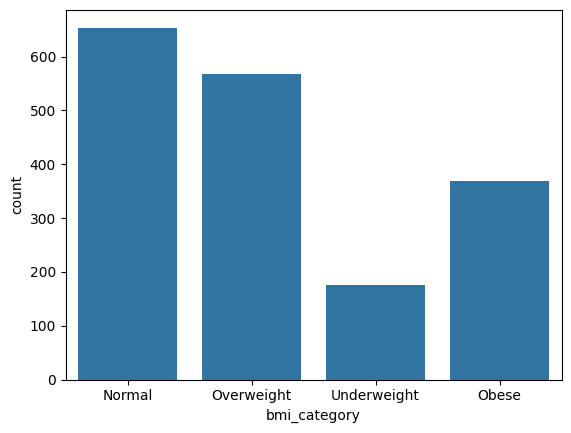

In [ ]:
sns.countplot(data = df, x="bmi_category")
display()

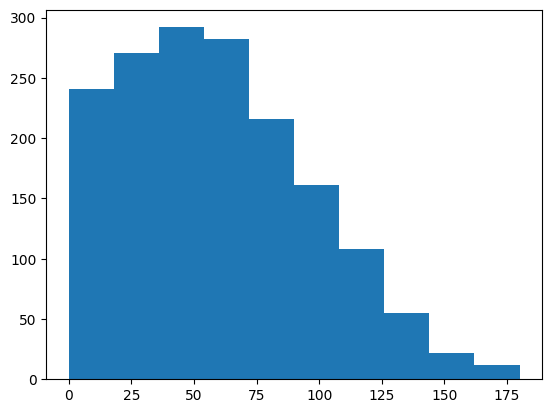

In [ ]:
plt.hist(df["physical_activity_level"])
plt.show()

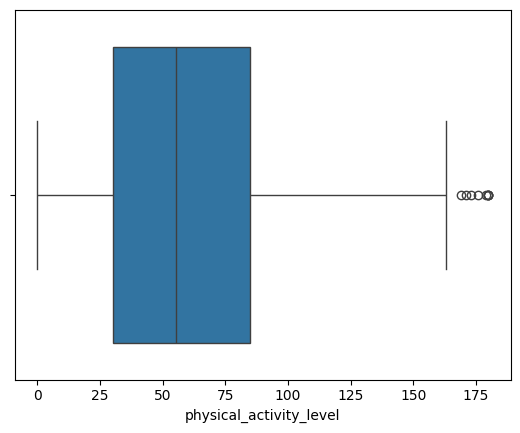

In [ ]:
sns.boxplot(data = df, x="physical_activity_level")
display()

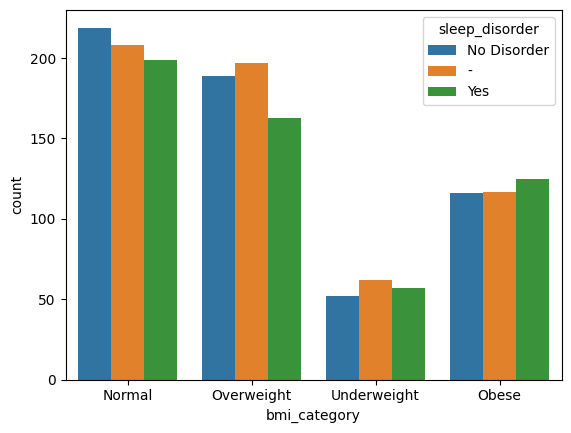

In [ ]:
sns.countplot(data=df, x="bmi_category", hue="sleep_disorder")
display()

1. Display the first 5 instances of the dataset

In [ ]:
df.head(5)

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
0,1,Male,41.0,Nurse,7.0,5.0,91.0,10.0,Normal,111/71.15,56.0,9476.0,No Disorder
1,2,Male,42.0,Software Engineer,402.0,7.0,123.0,5.0,Overweight,129/85.85000000000001,67.0,10661.0,No Disorder
2,3,Female,45.0,Doctor,8.7,4.0,49.0,7.0,Normal,119/79.35000000000001,60.0,5033.0,No Disorder
3,4,Male,24.0,Writer,8.0,6.0,NaN,5.0,Normal,98/62.7,97.0,1610.0,No Disorder
4,5,female,18.0,Salesperson,8.8,6.0,66.0,4.0,Overweight,110/66.5,71.0,6574.0,-


2. Display the last 10 instances of the dataset

In [ ]:
df.tail(10)

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
1990,1991,Female,23.0,Manager,9.4,5.0,58.0,7.0,NaN,103/69.95,75.0,7540.0,No Disorder
1991,1992,F,71.0,Writer,6.8,4.0,35.0,4.0,Overweight,120/81.0,81.0,3750.0,-
1992,1993,M,52.0,Engineer,498.0,8.0,37.0,2.0,NaN,122/81.3,77.0,4895.0,No Disorder
1993,1994,Male,34.0,Doctor,6.0,5.0,26.0,10.0,Obese,135/84.75,104.0,1725.0,Yes
1994,1995,Male,48.0,Software Engineer,8.4,9.0,42.0,3.0,Overweight,132/82.8,64.0,3830.0,-
1995,1996,male,47.0,Lawyer,8.6,6.0,73.0,7.0,Normal,109/71.85000000000001,80.0,4742.0,-
1996,1997,male,41.0,Manager,402.0,2.0,NaN,10.0,Obese,139/94.35000000000001,102.0 bpm,3944.0,Yes
1997,1998,male,66.0,Chef,8.2,1.0,99.0,8.0,Normal,123/76.95,77.0,11116.0,NaN
1998,1999,M,43.0,Accountant,7.9,8.0,25.0,5.0,Obese,129/78.85000000000001,65.0,3286.0,No Disorder
1999,2000,female,61.0,Writer,8.7,6.0,47.0,5.0,Overweight,130/83.5,77.0,6585.0,-


3.a. What is the average age of the patients? THe minimum? The maximum?

In [ ]:
(df['age'].mean(), df['age'].max(), df['age'].min())

(np.float64(48.9735), 1200.0, -25.0)

In [ ]:
3.b. How many people are there per stress level?

Object `level` not found.


In [ ]:
df['stress_level'].value_counts()

,count
stress_level,
7.0,310
8.0,282
6.0,277
5.0,277
9.0,202
4.0,191
3.0,148
10.0,136
1.0,93


3.c. How many paople exercise more than 30 minutes a day?

In [ ]:
len(df[df["physical_activity_level"] > 30])

1234

3.d. What was the average age by sleep quality level?

In [ ]:
df[['quality_of_sleep','age']].groupby(['quality_of_sleep']).mean()

,age
quality_of_sleep,
1.0,63.727273
2.0,55.520000
3.0,57.472000
4.0,51.356557
5.0,51.767263
6.0,46.431325
7.0,45.701333
8.0,45.473934
9.0,45.255102


3.e. What is the average age of the people with sleep disorder? The minimum? The maximum?

In [ ]:
df_sleep_disorder_yes = df[df['sleep_disorder'] == 'Yes'] ## Gemini's solution
print(f"Average age for people with sleep disorder: {df_sleep_disorder_yes['age'].mean():.2f}")
print(f"Minimum age for people with sleep disorder: {df_sleep_disorder_yes['age'].min():.2f}")
print(f"Maximum age for people with sleep disorder: {df_sleep_disorder_yes['age'].max():.2f}")

Average age for people with sleep disorder: 51.78
Minimum age for people with sleep disorder: 18.00
Maximum age for people with sleep disorder: 1200.00


In [ ]:
sleep_disorder = df[df['sleep_disorder'] == 'Yes'] ## Teacher's solution
(sleep_disorder['age'].mean(), sleep_disorder['age'].max(), sleep_disorder['age'].min())

(np.float64(51.78365384615385), 1200.0, 18.0)

3.f. Create a graph of patients by stress level

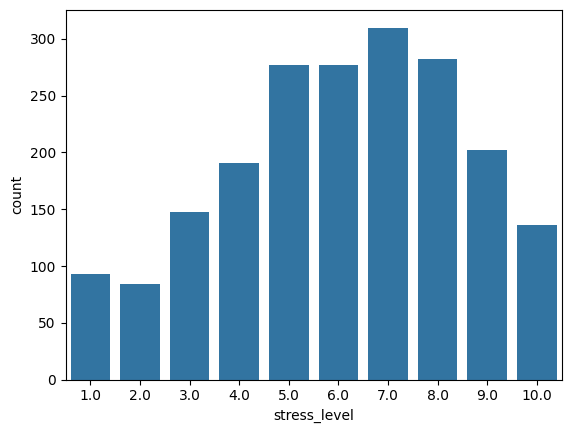

In [ ]:
sns.countplot(data=df, x="stress_level")
display()

3.g. Create a histogram of any continuous numerical value (age in this case)

<Axes: >

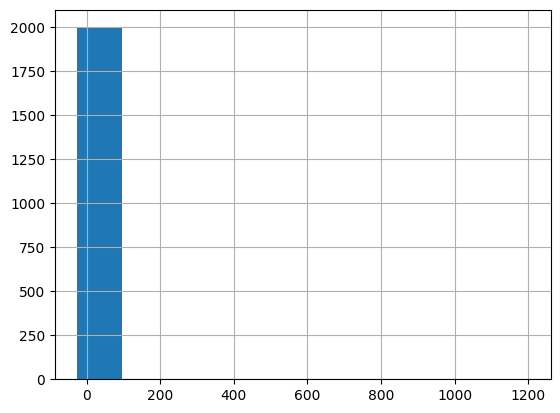

In [ ]:
df['age'].hist()

## Data quality issues

### Physical activity (missing values)

<Axes: >

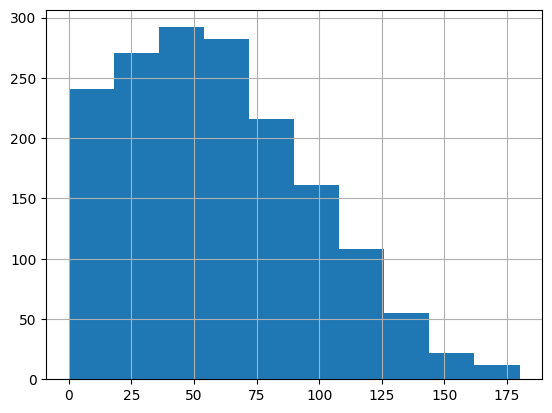

In [ ]:
## Imputation: Replacing the missing values with mean, median or mode
df['physical_activity_level'].hist()

In [ ]:
## Because the graph is skewed right, the median is more appropiate than the mean
df['physical_activity_level'].fillna(df['physical_activity_level'].median(), inplace = True)

/tmp/ipykernel_1386/1142130428.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['physical_activity_level'].fillna(df['physical_activity_level'].median(), inplace = True)


### Gender (irregular cardinality)


In [ ]:
df['gender'].value_counts()

,count
gender,
F,358
female,343
male,334
Male,333
Female,325
M,307


In [ ]:
## Group M, male and Male under M; and F, female and Female under F
df['gender'] = df['gender'].replace({'Female' : 'F', 'female' : 'F', 'Male' : 'M', 'male' : 'M'})

In [ ]:
df['gender'].value_counts()

,count
gender,
F,1026
M,974


### Age (outliers)

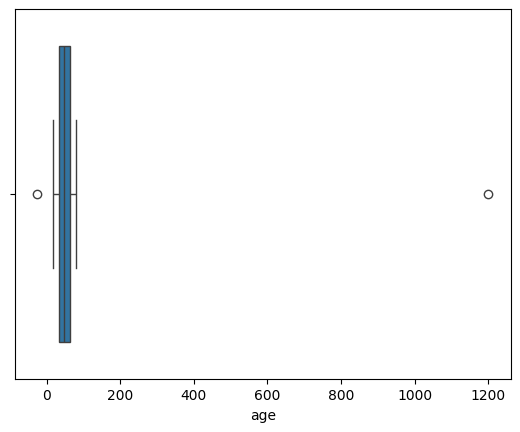

In [ ]:
sns.boxplot(data = df, x = "age")
display()

In [ ]:
## Cap the upper age limit to 100
df = df[df['age'] < 100]

In [ ]:
## Cap the lower age limit to 0
df = df[df['age'] > 0]

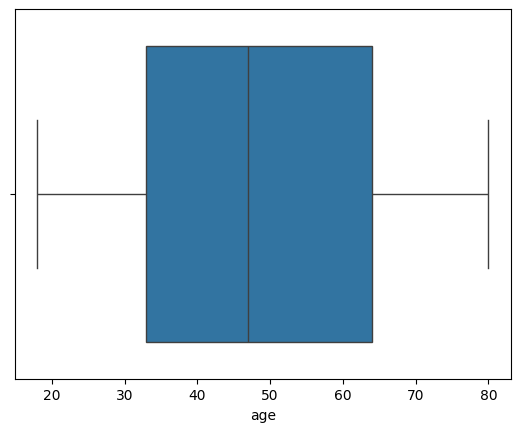

In [ ]:
sns.boxplot(data = df, x = "age")
display()

In [ ]:
df.describe(include = "all")

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
count,1998.000000,1998,1998.000000,1998,1998.000000,1998.000000,1998.000000,1998.000000,1764,1998,1998,1998.000000,1933
unique,NaN,2,NaN,19,NaN,NaN,NaN,NaN,4,474,120,NaN,3
top,NaN,F,NaN,Chef,NaN,NaN,NaN,NaN,Normal,118/74.7,71.0,NaN,-
freq,NaN,1025,NaN,144,NaN,NaN,NaN,NaN,653,17,71,NaN,662
mean,1000.522022,NaN,48.434434,NaN,62.317367,5.802803,58.413413,6.059059,NaN,NaN,NaN,6096.722723,NaN
std,577.736022,NaN,18.113907,NaN,149.457576,1.894343,34.760786,2.396065,NaN,NaN,NaN,2850.675709,NaN
min,1.000000,NaN,18.000000,NaN,4.800000,1.000000,0.000000,1.000000,NaN,NaN,NaN,1000.000000,NaN
25%,500.250000,NaN,33.000000,NaN,7.200000,5.000000,35.000000,4.000000,NaN,NaN,NaN,3941.000000,NaN
50%,1000.500000,NaN,47.000000,NaN,7.900000,6.000000,55.500000,6.000000,NaN,NaN,NaN,5792.000000,NaN
75%,1500.750000,NaN,64.000000,NaN,8.700000,7.000000,78.000000,8.000000,NaN,NaN,NaN,7958.750000,NaN


### Sleep duration (outliers)

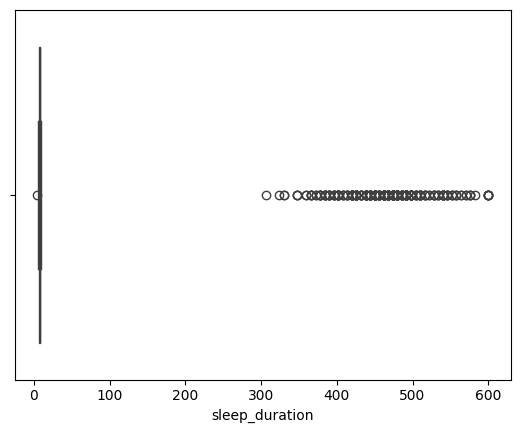

In [ ]:
sns.boxplot(data = df, x = "sleep_duration")
display()

In analyzing the boxplot, we can see that are a huge number of values that are outliers. They are impossible values. So, we thought that it could be a mistake of different measurement. Instead of putting the hours that a person sleep, it may be the minutes that a person sleep. So, our final decision is to divide the values greater than 300 by 60, to change from minutes to hours.

In [ ]:
df.loc[df['sleep_duration'] > 300, 'sleep_duration'] = df.loc[df['sleep_duration'] > 300, 'sleep_duration'] / 60 ##esto nos sirve para todos los datos mayores de 300 ponerlos en segundos

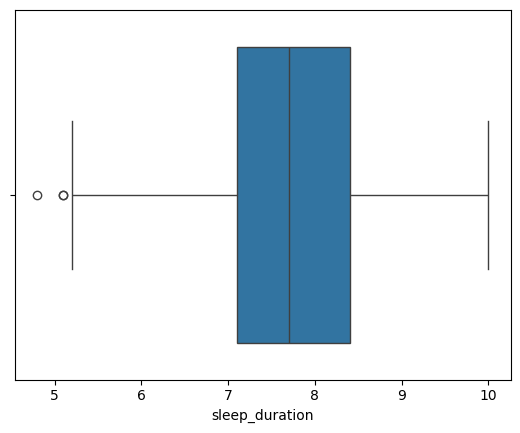

In [ ]:
sns.boxplot(data = df, x = "sleep_duration")
display()

### BMI category (missing values)

We have 1764 values for the feature bmi_category. It is missing 234 values, 12%. What we decided to do is to substitute the missing values with an estimated value. For that purpose, in that bmi_category is not a numerical value, we decided to use the mode to estimate the missing values.

In [ ]:
df['bmi_category'].value_counts()

,count
bmi_category,
Normal,653
Overweight,566
Obese,369
Underweight,176


In [ ]:
df['bmi_category'] = df['bmi_category'].fillna(df['bmi_category'].mode()[0]) ## To change the missing value to the mode

In [ ]:
df['bmi_category'].value_counts()

,count
bmi_category,
Normal,887
Overweight,566
Obese,369
Underweight,176


### Heart rate (irregular cardinality)

Incorret format of the heart_rate column.
We have two formats. Just the number of bpm, and the number of bpm + the word bmp. We eliminate those rows with the second format to leave just the rows with the number. After that, we change the data type of the column to a float.

In [ ]:
df['heart_rate'].value_counts()

,count
heart_rate,
71.0,71
75.0,63
79.0,62
76.0,55
72.0,55
...,...
49.0 bpm,1
99.0 bpm,1
44.0,1


In [ ]:
df['heart_rate'] = df['heart_rate'].astype(str).str.replace('bpm', '', case=False).str.strip() ## Replace the word 'bmp' with ''

In [ ]:
df['heart_rate'] = df['heart_rate'].astype(float) ## Change the datatype of the column to float

In [ ]:
df['heart_rate'].value_counts()

,count
heart_rate,
71.0,76
75.0,69
79.0,67
72.0,63
74.0,61
...,...
42.0,1
40.0,1
41.0,1


In [ ]:
df.describe(include = "all")

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
count,1998.000000,1998,1998.000000,1998,1998.000000,1998.000000,1998.000000,1998.000000,1998,1998,1998.000000,1998.000000,1933
unique,NaN,2,NaN,19,NaN,NaN,NaN,NaN,4,474,NaN,NaN,3
top,NaN,F,NaN,Chef,NaN,NaN,NaN,NaN,Normal,118/74.7,NaN,NaN,-
freq,NaN,1025,NaN,144,NaN,NaN,NaN,NaN,887,17,NaN,NaN,662
mean,1000.522022,NaN,48.434434,NaN,7.752703,5.802803,58.413413,6.059059,NaN,NaN,74.888388,6096.722723,NaN
std,577.736022,NaN,18.113907,NaN,0.946019,1.894343,34.760786,2.396065,NaN,NaN,12.518751,2850.675709,NaN
min,1.000000,NaN,18.000000,NaN,4.800000,1.000000,0.000000,1.000000,NaN,NaN,40.000000,1000.000000,NaN
25%,500.250000,NaN,33.000000,NaN,7.100000,5.000000,35.000000,4.000000,NaN,NaN,66.000000,3941.000000,NaN
50%,1000.500000,NaN,47.000000,NaN,7.700000,6.000000,55.500000,6.000000,NaN,NaN,74.500000,5792.000000,NaN
75%,1500.750000,NaN,64.000000,NaN,8.400000,7.000000,78.000000,8.000000,NaN,NaN,83.000000,7958.750000,NaN


### Sleep disorder (irregular cardinality and missing values)

In [ ]:
df['sleep_disorder'].value_counts()

,count
sleep_disorder,
-,662
No Disorder,648
Yes,623


Once we checked te sleep disorder column, we discover two problems. The first one is that 65 values are missing, so, in that it is the target feature, we decided to eliminate that rows with missing values. The second one is that having no disorder is stored in two different ways: '-' and 'No disorder', so we have to name it under the same name.

In [ ]:
df= df.dropna(subset=['sleep_disorder'])

In [ ]:
df['sleep_disorder'] = df['sleep_disorder'].replace({'-' : 'No Disorder'})

In [ ]:
df.describe(include = "all")

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
count,1933.000000,1933,1933.000000,1933,1933.000000,1933.000000,1933.000000,1933.000000,1933,1933,1933.000000,1933.000000,1933
unique,NaN,2,NaN,19,NaN,NaN,NaN,NaN,4,470,NaN,NaN,2
top,NaN,F,NaN,Chef,NaN,NaN,NaN,NaN,Normal,118/74.7,NaN,NaN,No Disorder
freq,NaN,985,NaN,139,NaN,NaN,NaN,NaN,856,16,NaN,NaN,1310
mean,1001.565442,NaN,48.441800,NaN,7.752043,5.807553,58.534920,6.070357,NaN,NaN,74.871702,6101.744956,NaN
std,577.578667,NaN,18.163319,NaN,0.948695,1.902707,34.825135,2.397854,NaN,NaN,12.536741,2848.074420,NaN
min,1.000000,NaN,18.000000,NaN,4.800000,1.000000,0.000000,1.000000,NaN,NaN,40.000000,1000.000000,NaN
25%,502.000000,NaN,33.000000,NaN,7.100000,5.000000,35.000000,4.000000,NaN,NaN,66.000000,3944.000000,NaN
50%,1001.000000,NaN,47.000000,NaN,7.700000,6.000000,55.500000,6.000000,NaN,NaN,74.000000,5790.000000,NaN
75%,1502.000000,NaN,64.000000,NaN,8.400000,7.000000,78.000000,8.000000,NaN,NaN,83.000000,7979.000000,NaN


### Blood pressure (irregular cardinality)

In [ ]:
df['blood_pressure'].value_counts()

,count
blood_pressure,
118/74.7,16
118/78.7,14
117/75.05,13
124/75.60000000000001,13
118/75.7,13
...,...
139/87.35000000000001,1
102/62.3,1
145/90.25,1


In [ ]:
df[['systolic_pressure', 'diastolic_pressure']] = df['blood_pressure'].str.split('/', expand=True)

In [ ]:
df['systolic_pressure'] = df['systolic_pressure'].astype(float)
df['diastolic_pressure'] = df['diastolic_pressure'].astype(float)

In [ ]:
df = df.drop(columns=['blood_pressure'])

In [ ]:
df.describe(include = "all")

,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,heart_rate,daily_steps,sleep_disorder,systolic_pressure,diastolic_pressure
count,1933.000000,1933,1933.000000,1933,1933.000000,1933.000000,1933.000000,1933.000000,1933,1933.000000,1933.000000,1933,1933.000000,1933.000000
unique,NaN,2,NaN,19,NaN,NaN,NaN,NaN,4,NaN,NaN,2,NaN,NaN
top,NaN,F,NaN,Chef,NaN,NaN,NaN,NaN,Normal,NaN,NaN,No Disorder,NaN,NaN
freq,NaN,985,NaN,139,NaN,NaN,NaN,NaN,856,NaN,NaN,1310,NaN,NaN
mean,1001.565442,NaN,48.441800,NaN,7.752043,5.807553,58.534920,6.070357,NaN,74.871702,6101.744956,NaN,120.236937,78.040300
std,577.578667,NaN,18.163319,NaN,0.948695,1.902707,34.825135,2.397854,NaN,12.536741,2848.074420,NaN,10.570122,7.495074
min,1.000000,NaN,18.000000,NaN,4.800000,1.000000,0.000000,1.000000,NaN,40.000000,1000.000000,NaN,97.000000,60.000000
25%,502.000000,NaN,33.000000,NaN,7.100000,5.000000,35.000000,4.000000,NaN,66.000000,3944.000000,NaN,113.000000,72.750000
50%,1001.000000,NaN,47.000000,NaN,7.700000,6.000000,55.500000,6.000000,NaN,74.000000,5790.000000,NaN,120.000000,77.800000
75%,1502.000000,NaN,64.000000,NaN,8.400000,7.000000,78.000000,8.000000,NaN,83.000000,7979.000000,NaN,128.000000,83.250000


### Occupation (irregular cardinality)

In [ ]:
df['occupation'].value_counts()

,count
occupation,
Chef,139
Student,138
Artist,131
Software Engineer,130
Nurse,128
Salesperson,127
Manager,126
Accountant,122
Lawyer,122


In [ ]:
df['occupation'] = df['occupation'].replace({'Sales Representative' : 'Salesperson', 'lawyer' : 'Lawyer', 'doctor' : 'Doctor', 'engineer' : 'Engineer', 'teacher' : 'Teacher'})

In [ ]:
df['occupation'].value_counts()

,count
occupation,
Salesperson,248
Lawyer,144
Chef,139
Student,138
Artist,131
Doctor,131
Software Engineer,130
Teacher,128
Nurse,128


In [ ]:
df.isnull().sum()

,0
person_id,0
gender,0
age,0
occupation,0
sleep_duration,0
quality_of_sleep,0
physical_activity_level,0
stress_level,0
bmi_category,0
heart_rate,0


## Relationships between features

### Teacher's explanation

`2 continuous features`

<Axes: xlabel='daily_steps', ylabel='physical_activity_level'>

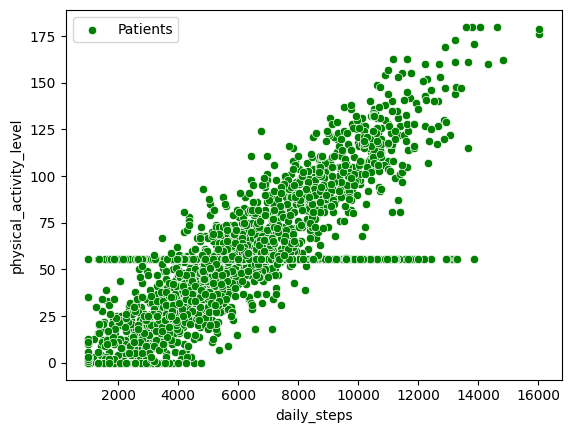

In [ ]:
sns.scatterplot(data = df, x = 'daily_steps', y = 'physical_activity_level', color = 'green', label = 'Patients')

`2 categorical features`

/usr/local/lib/python3.12/dist-packages/IPython/core/displayhook.py:275: UserWarning: Output cache limit (currently 1000 entries) hit.
Flushing oldest 200 entries.
  warn('Output cache limit (currently {sz} entries) hit.\n'


<Axes: xlabel='bmi_category', ylabel='count'>

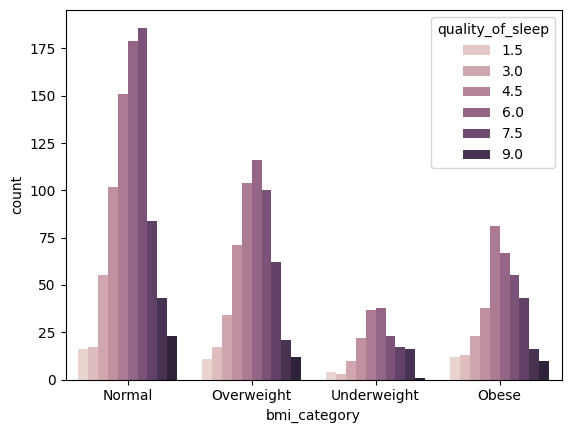

In [ ]:
sns.countplot(data = df, x = 'bmi_category', hue = 'quality_of_sleep')

`1 continuous feature and 1 categorical feature`

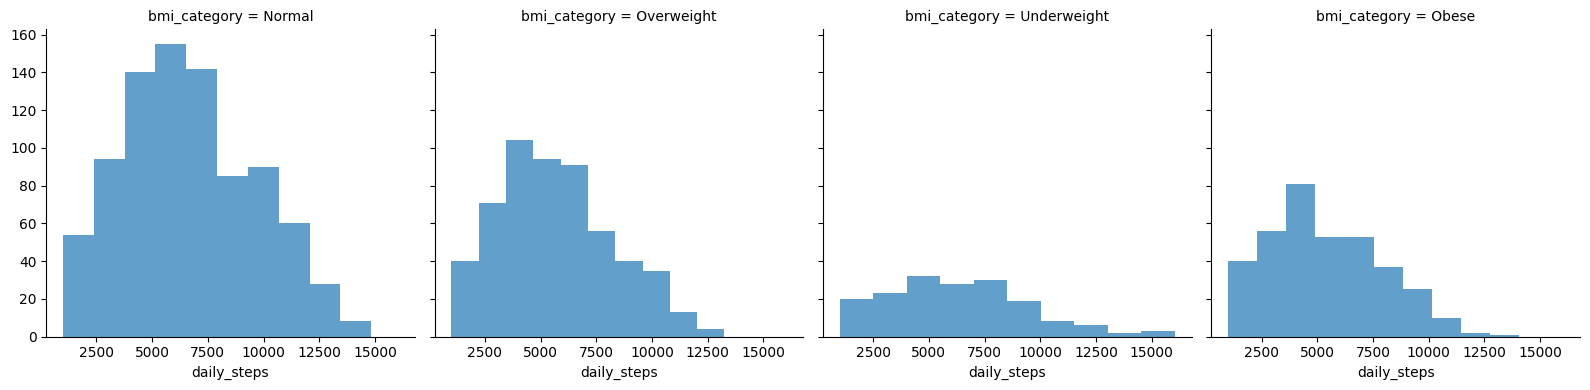

In [ ]:
graph = sns.FacetGrid(df, col = 'bmi_category', height = 4)
graph.map(plt.hist, 'daily_steps', bins = 10, alpha = 0.7)

<Axes: xlabel='bmi_category', ylabel='daily_steps'>

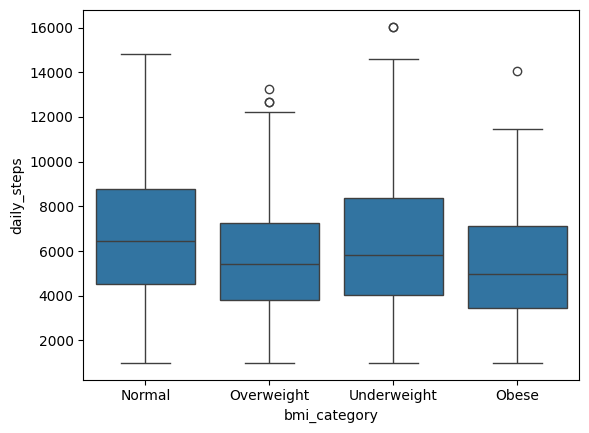

In [ ]:
sns.boxplot(data = df, x = 'bmi_category', y = 'daily_steps')

### Correlation

In [ ]:
corr_matrix = df.corr(numeric_only = True)
corr_matrix

,person_id,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,systolic_pressure,diastolic_pressure
person_id,1.000000,-0.016630,0.002196,-0.001724,-0.003710,0.019701,0.033843,-0.009677,0.014413,0.007768
age,-0.016630,1.000000,0.010641,-0.208385,-0.015312,-0.005432,-0.002342,-0.019557,0.345886,0.305564
sleep_duration,0.002196,0.010641,1.000000,0.182616,0.042550,-0.472238,-0.062459,0.046692,-0.023338,-0.029928
quality_of_sleep,-0.001724,-0.208385,0.182616,1.000000,0.125771,-0.305497,-0.145615,0.128896,-0.102580,-0.096439
physical_activity_level,-0.003710,-0.015312,0.042550,0.125771,1.000000,0.051367,-0.404731,0.829951,-0.159007,-0.161592
stress_level,0.019701,-0.005432,-0.472238,-0.305497,0.051367,1.000000,0.050112,0.042123,0.008082,-0.002652
heart_rate,0.033843,-0.002342,-0.062459,-0.145615,-0.404731,0.050112,1.000000,-0.418559,0.118256,0.122658
daily_steps,-0.009677,-0.019557,0.046692,0.128896,0.829951,0.042123,-0.418559,1.000000,-0.144517,-0.154308
systolic_pressure,0.014413,0.345886,-0.023338,-0.102580,-0.159007,0.008082,0.118256,-0.144517,1.000000,0.908722
diastolic_pressure,0.007768,0.305564,-0.029928,-0.096439,-0.161592,-0.002652,0.122658,-0.154308,0.908722,1.000000


<Axes: >

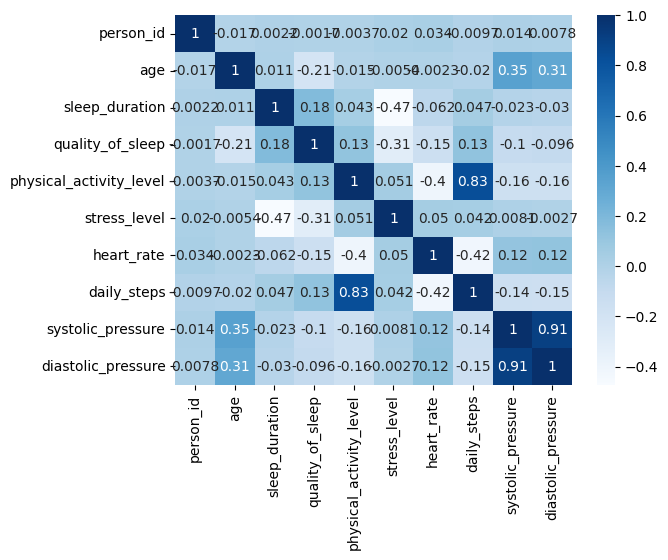

In [ ]:
sns.heatmap(corr_matrix, cmap = 'Blues', annot = True)

We dont have the target feature in the correlation matrix because it is not numeric, so we have to change it to numerical

In [ ]:
df['sleep_disorder'] = df['sleep_disorder'].replace({'Yes' : 1, 'No Disorder' : 0}) ## Convert sleep_disorder into numerical

/tmp/ipykernel_1386/917410518.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sleep_disorder'] = df['sleep_disorder'].replace({'Yes' : 1, 'No Disorder' : 0}) ## Convert sleep_disorder into numerical


In [ ]:
corr_matrix = df.corr(numeric_only = True)
corr_matrix

,person_id,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,sleep_disorder,systolic_pressure,diastolic_pressure
person_id,1.000000,-0.016630,0.002196,-0.001724,-0.003710,0.019701,0.033843,-0.009677,-0.134390,0.014413,0.007768
age,-0.016630,1.000000,0.010641,-0.208385,-0.015312,-0.005432,-0.002342,-0.019557,0.056921,0.345886,0.305564
sleep_duration,0.002196,0.010641,1.000000,0.182616,0.042550,-0.472238,-0.062459,0.046692,-0.091527,-0.023338,-0.029928
quality_of_sleep,-0.001724,-0.208385,0.182616,1.000000,0.125771,-0.305497,-0.145615,0.128896,-0.100151,-0.102580,-0.096439
physical_activity_level,-0.003710,-0.015312,0.042550,0.125771,1.000000,0.051367,-0.404731,0.829951,-0.047635,-0.159007,-0.161592
stress_level,0.019701,-0.005432,-0.472238,-0.305497,0.051367,1.000000,0.050112,0.042123,0.139065,0.008082,-0.002652
heart_rate,0.033843,-0.002342,-0.062459,-0.145615,-0.404731,0.050112,1.000000,-0.418559,0.070736,0.118256,0.122658
daily_steps,-0.009677,-0.019557,0.046692,0.128896,0.829951,0.042123,-0.418559,1.000000,-0.066172,-0.144517,-0.154308
sleep_disorder,-0.134390,0.056921,-0.091527,-0.100151,-0.047635,0.139065,0.070736,-0.066172,1.000000,0.051054,0.039390
systolic_pressure,0.014413,0.345886,-0.023338,-0.102580,-0.159007,0.008082,0.118256,-0.144517,0.051054,1.000000,0.908722


<Axes: >

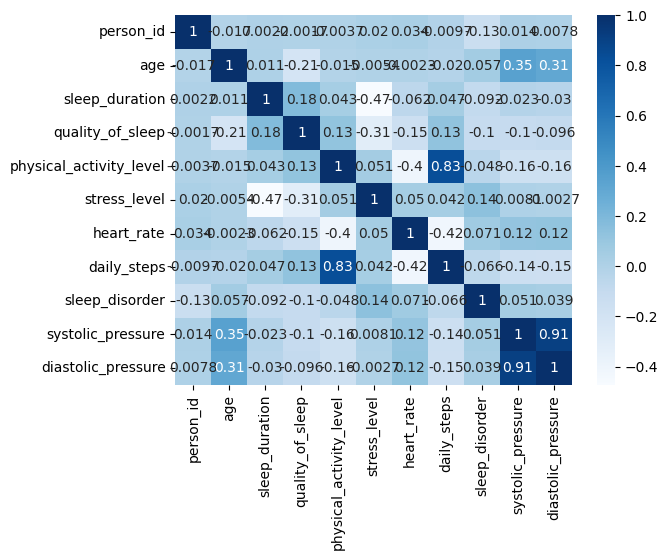

In [ ]:
sns.heatmap(corr_matrix, cmap = 'Blues', annot = True)

## Relationships between descriptive features and the target feature

### Relationships

`GENDER VS SLEEP DISORDER`

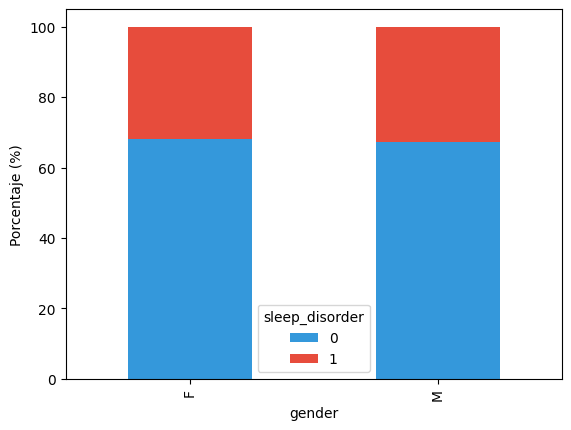

In [ ]:
tabla = pd.crosstab(df['gender'], df['sleep_disorder'], normalize='index') * 100 ## Create a table with row percentages multiplied by 100
tabla.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c']) ## Plot the table as a stacked bar chart using blue and red colors
plt.ylabel('Porcentaje (%)') ## Add a label to the y axis
plt.show() ## Show the graph

With this graph, we can assume that there is no relation between the two features, in that the proportion appear similar across all bars

`AGE VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='age'>

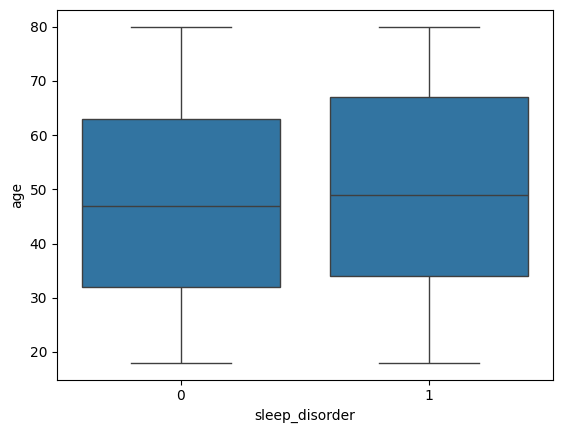

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'age')

With this boxplot, we can see that the higher the age is, the higher the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only 0.057, which is relatively low

`OCCUPATION VS SLEEP DISORDER`

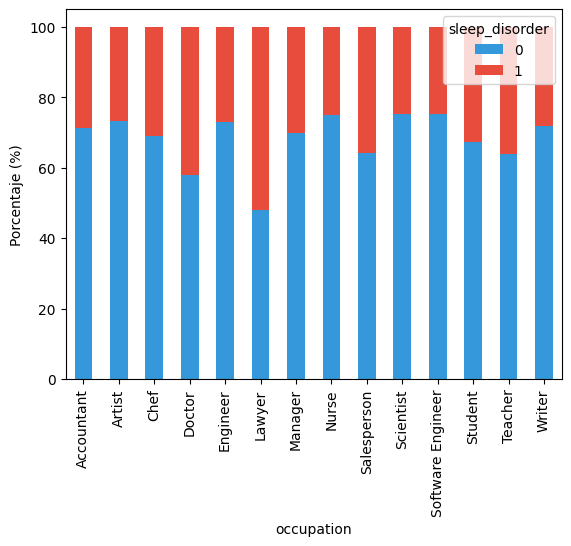

In [ ]:
tabla = pd.crosstab(df['occupation'], df['sleep_disorder'], normalize='index') * 100 ## Create a table with row percentages multiplied by 100
tabla.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c']) ## Plot the table as a stacked bar chart using blue and red colors
plt.ylabel('Porcentaje (%)') ## Add a label to the y axis
plt.show() ## Show the graph

With this graph, we can assume that there is no relation between the two features, in that the proportion appear similar across all bars

`SLEEP DURATION VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='sleep_duration'>

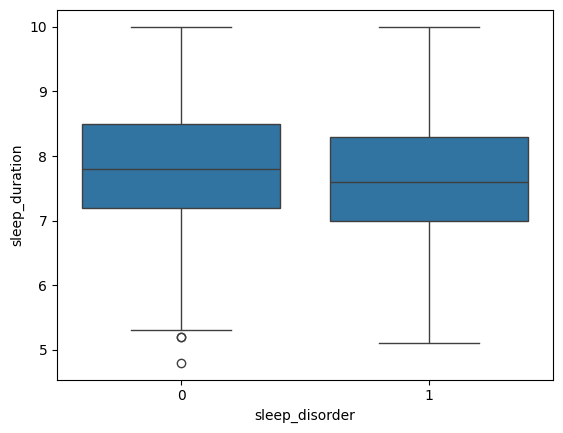

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'sleep_duration')

With this boxplot, we can see that the higher the duration of sleep is, the lower the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only -0.092, which relatively low

`QUALITY OF SLEEP VS SLEEP DISORDER`

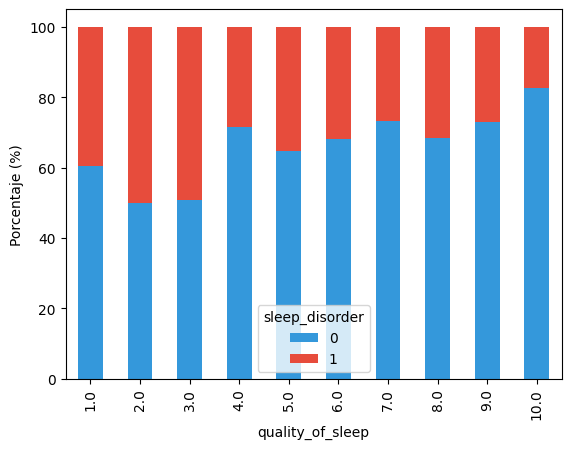

In [ ]:
tabla = pd.crosstab(df['quality_of_sleep'], df['sleep_disorder'], normalize='index') * 100 ## Create a table with row percentages multiplied by 100
tabla.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c']) ## Plot the table as a stacked bar chart using blue and red colors
plt.ylabel('Porcentaje (%)') ## Add a label to the y axis
plt.show() ## Show the graph

With this graph, we can see a slight relation between the two variables. The higher the quality of sleep is, the lower the chances of sleep disorder. However, we don't know exactly what is direction of causality. We don't know whether a person has a bad quality of sleep because of having a sleep disorder, or a person has a sleep disorder due to a poor quality of sleep

`PHYSICAL ACTIVIY LEVEL`

<Axes: xlabel='sleep_disorder', ylabel='physical_activity_level'>

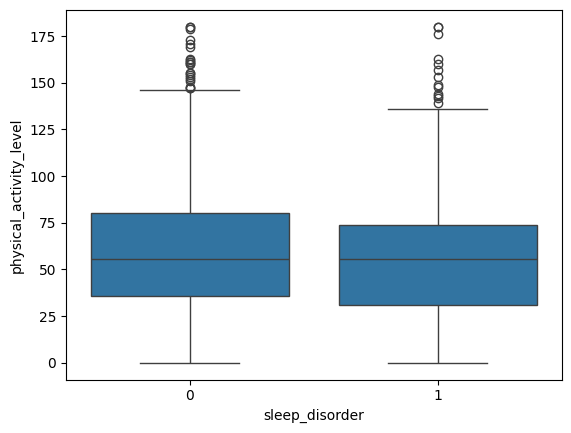

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'physical_activity_level')

With this boxplot, we can see that the higher the minutes of physical activity are, the lower the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only -0.048, which relatively low

`STRESS LEVEL VS SLEEP DISORDER`

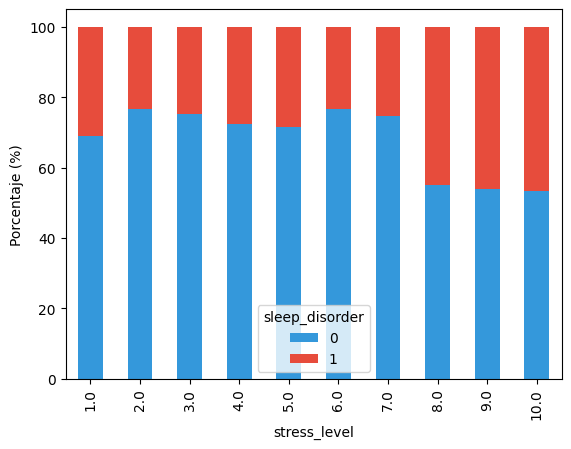

In [ ]:
tabla = pd.crosstab(df['stress_level'], df['sleep_disorder'], normalize='index') * 100 ## Create a table with row percentages multiplied by 100
tabla.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c']) ## Plot the table as a stacked bar chart using blue and red colors
plt.ylabel('Porcentaje (%)') ## Add a label to the y axis
plt.show() ## Show the graph

With this graph, we can see a slight relation between the two variables. The higher the stress level is, the higher the chances of sleep disorder. However, we don't know exactly what is direction of causality. We don't know whether a person has a high stress level because of having a sleep disorder, or a person has a sleep disorder due to a high stress level

`BMI CATEGORY VS SLEEP DISORDER`

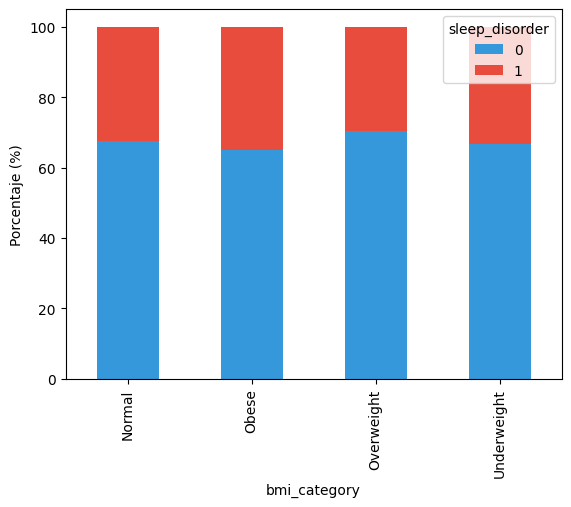

In [ ]:
tabla = pd.crosstab(df['bmi_category'], df['sleep_disorder'], normalize='index') * 100 ## Create a table with row percentages multiplied by 100
tabla.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c']) ## Plot the table as a stacked bar chart using blue and red colors
plt.ylabel('Porcentaje (%)') ## Add a label to the y axis
plt.show() ## Show the graph

With this graph, we can assume that there is no relation between the two features, in that the proportion appear similar across all bars

`HEART RATE VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='heart_rate'>

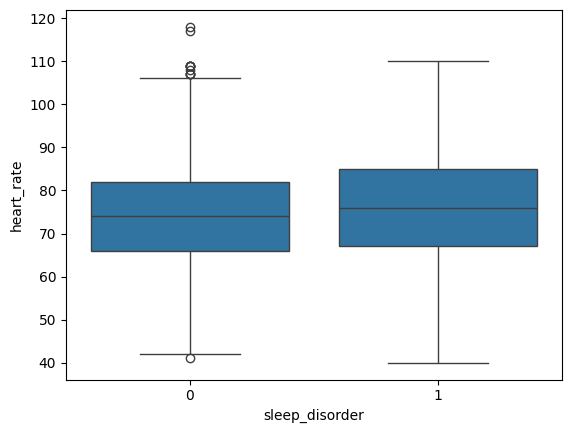

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'heart_rate')

With this boxplot, we can see that the higher the heart rate is, the higher the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only 0.071, which relatively low

`DAILY STEPS VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='daily_steps'>

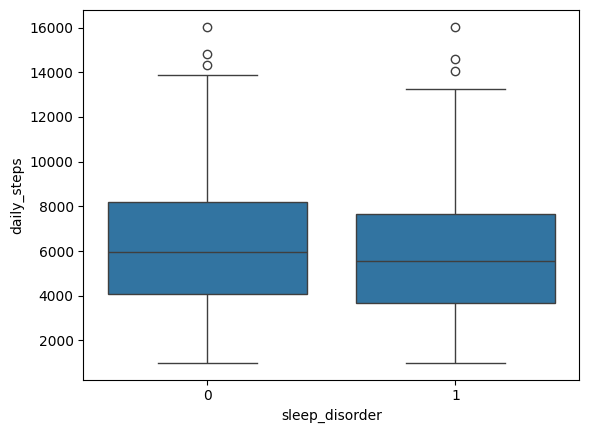

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'daily_steps')

With this boxplot, we can see that the higher the daily steps are, the lower the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only -0.066, which relatively low

`SYSTOLIC PRESSURE VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='systolic_pressure'>

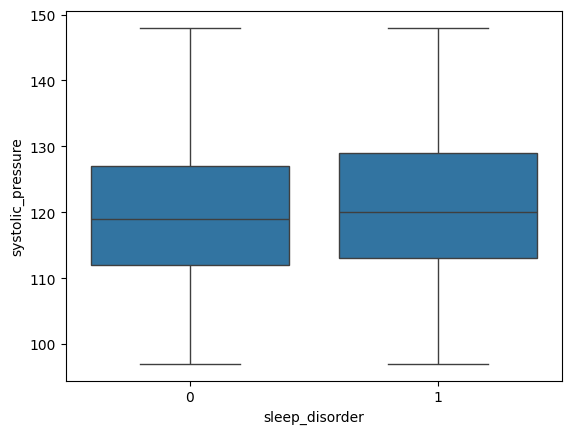

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'systolic_pressure')

With this boxplot, we can see that the higher the diastolic pressure is, the higher the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only 0.051, which relatively low

`DIASTOLIC PRESSURE VS SLEEP DISORDER`

<Axes: xlabel='sleep_disorder', ylabel='diastolic_pressure'>

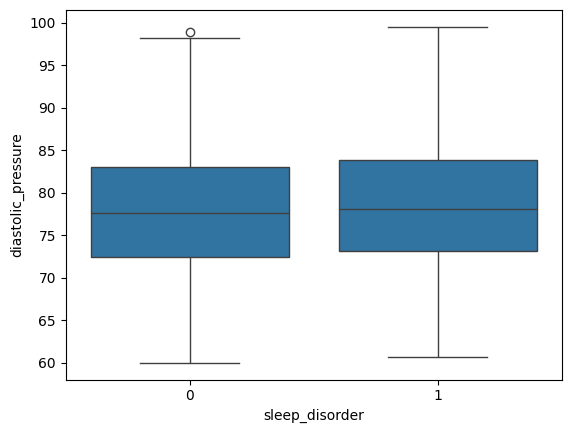

In [ ]:
sns.boxplot(data = df, x = 'sleep_disorder', y = 'diastolic_pressure')

With this boxplot, we can see that the higher the diastolic pressure is, the higher the chances of sleep disorder. However, the correlation matrix shows us that the correlation is only 0.039, which is relatively low

### Candidate features


Looking at the charts and numbers, the three main things that predict a sleep_disorder are stress_level, quality_of_sleep, and sleep_duration. Stress level has the strongest link (0.14). This simply means that more stress goes hand in hand with having more sleep problems. Sleep quality (-0.100) and sleep duration (-0.092) work the opposite way. Worse sleep quality and shorter sleeping hours are both linked to having a sleep disorder.

Other things like age, heart rate, daily steps, activity level, and blood pressure showed little connection (all below |0.08|) and don't help much on their own. Finally, things like gender, job, and BMI category didn't show any real link to sleep disorders.

## Additional analysis

`SLEEP DISORDER CORRELATION WITH A COMBINED INDEX OF FEATURES`

In [ ]:
variables = [
    'stress_level',
    'quality_of_sleep',
    'sleep_duration',
    'heart_rate',
    'daily_steps'
]

In [ ]:
valores_z = StandardScaler().fit_transform(df[variables])


In [ ]:
z = pd.DataFrame(
    valores_z,
    columns=variables,
    index=df.index
)

In [ ]:
risk_components = z.rename(columns={
    'stress_level': 'stress_risk',
    'quality_of_sleep': 'low_quality_risk',
    'sleep_duration': 'short_sleep_risk',
    'heart_rate': 'heart_rate_risk',
    'daily_steps': 'low_steps_risk'
})

In [ ]:
risk_components[['low_quality_risk', 'short_sleep_risk', 'low_steps_risk']] *= -1

In [ ]:
risk_components['sleep_risk_index'] = risk_components.mean(axis=1)


In [ ]:
pd.concat([risk_components['sleep_risk_index'], df['sleep_disorder']],axis=1).corr()

,sleep_risk_index,sleep_disorder
sleep_risk_index,1.000000,0.160017
sleep_disorder,0.160017,1.000000


`DIASTOLIC PRESSURE AND SYSTOLIC PRESSURE`

<Axes: xlabel='systolic_pressure', ylabel='diastolic_pressure'>

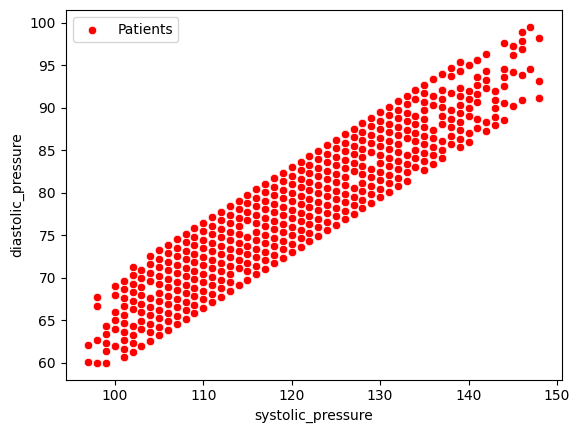

In [ ]:
sns.scatterplot(data = df, x = 'systolic_pressure', y = 'diastolic_pressure', color = 'red', label = 'Patients')

As can be seen in the graph, there is a strong correlation between systolic pressure and diastolic pressure

`PHYSICAL ACTIVITY LEVEL VS DAILY STEPS`

<Axes: xlabel='physical_activity_level', ylabel='daily_steps'>

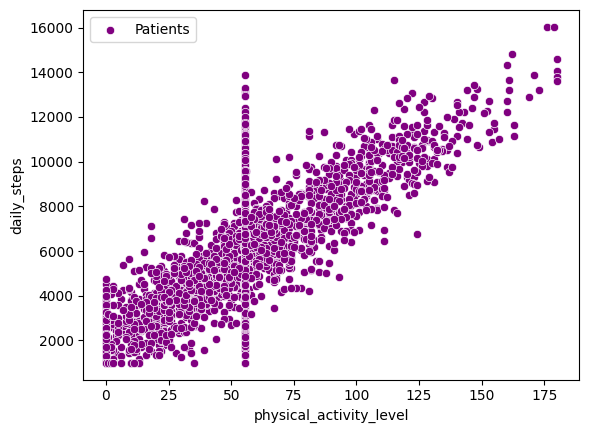

In [ ]:
sns.scatterplot(data = df, x = 'physical_activity_level', y = 'daily_steps', color = 'purple', label = 'Patients')

As can be seen in the graph, there is a strong correlation between systolic pressure and diastolic pressure

`AGE VS DIASTOLIC PRESSURE`

<Axes: xlabel='age', ylabel='diastolic_pressure'>

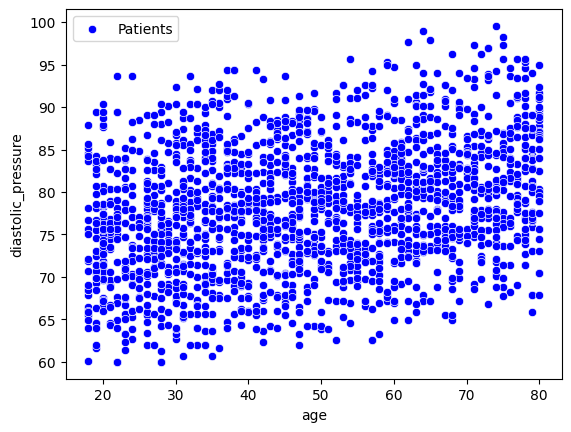

In [ ]:
sns.scatterplot(data = df, x = 'age', y = 'diastolic_pressure', color = 'blue', label = 'Patients')

As can be seen in the graph, there isnt strong correlation between age and diastolic pressure

`AGE VS SYSTOLIC PRESSURE`

<Axes: xlabel='age', ylabel='systolic_pressure'>

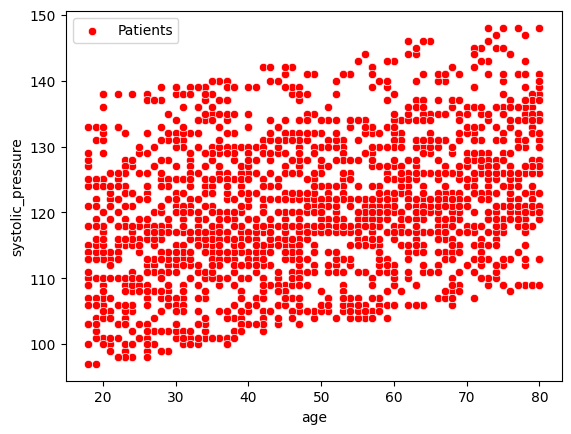

In [ ]:
sns.scatterplot(data = df, x = 'age', y = 'systolic_pressure', color = 'red', label = 'Patients')

As can be seen in the graph, there isnt a strong correlation between systolic pressure and age

`AVERAGE LEVEL OF FEATURES OF PATIENTS WITH SLEEP DISORDER AND PATIENTS WITHOUT SLEEP DISORDER`

In [ ]:
variables = [
    'stress_level',
    'quality_of_sleep',
    'sleep_duration',
    'heart_rate',
    'daily_steps',
    'sleep_risk_index'
]

In [ ]:
df_analysis = pd.concat(
    [df[variables[:-1] + ['sleep_disorder']],
     risk_components['sleep_risk_index']],
    axis=1
)

In [ ]:
df_analysis.groupby('sleep_disorder')[variables].mean()

,stress_level,quality_of_sleep,sleep_duration,heart_rate,daily_steps,sleep_risk_index
sleep_disorder,,,,,,
0,5.840458,5.938931,7.811908,74.260305,6231.679389,-0.064500
1,6.553772,5.531300,7.626164,76.157303,5828.528090,0.135626


`DISORDER BY STRESS LEVEL`

In [ ]:
stress_analysis = df.groupby(
    'stress_level'
)['sleep_disorder'].agg(['mean', 'count'])

stress_analysis

,mean,count
stress_level,,
1.0,0.311111,90
2.0,0.234568,81
3.0,0.246479,142
4.0,0.274725,182
5.0,0.284133,271
6.0,0.233962,265
7.0,0.254237,295
8.0,0.449275,276
9.0,0.460000,200


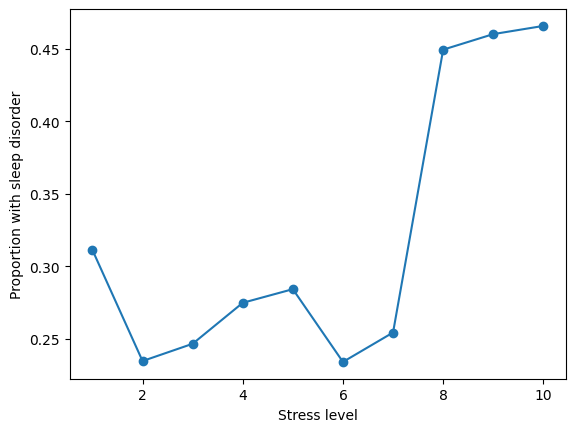

In [ ]:
stress_analysis['mean'].plot(marker='o')

plt.xlabel('Stress level')
plt.ylabel('Proportion with sleep disorder')
plt.show()

As can be seen in the graph, it seems that there is a significant jump in the proportion of sleep disorders from stress level 8 onwards

`LIFESTYLE COMPARISON`

                sleep_duration  quality_of_sleep  stress_level
sleep_disorder                                                
0                     7.811908          5.938931      5.840458
1                     7.626164          5.531300      6.553772


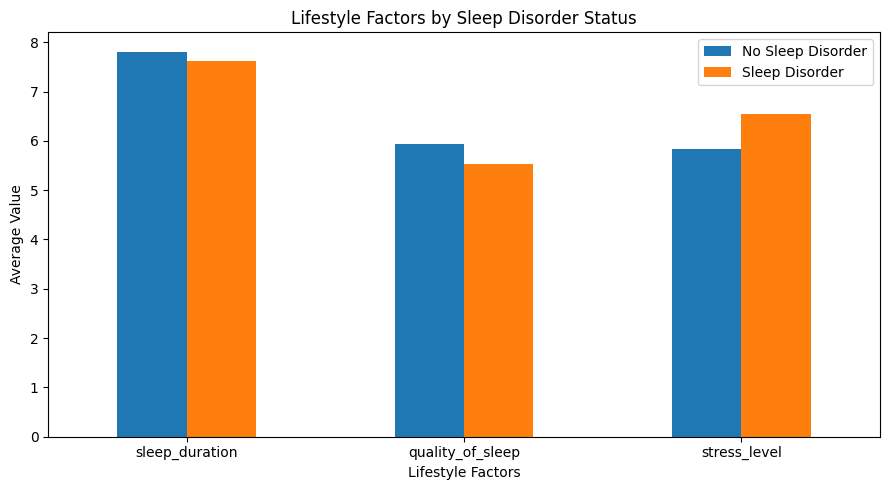

In [ ]:
lifestyle_comparison = df.groupby('sleep_disorder')[
    ['sleep_duration', 'quality_of_sleep', 'stress_level']
].mean()

print(lifestyle_comparison)

lifestyle_comparison.T.plot(kind='bar', figsize=(9, 5))

plt.title('Lifestyle Factors by Sleep Disorder Status')
plt.xlabel('Lifestyle Factors')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(['No Sleep Disorder', 'Sleep Disorder'])
plt.tight_layout()
plt.show()

Average lifestyle factors by sleep disorder status . The graph compares average sleep duration, sleep quality and stress level between people with and without sleep disorders. People with sleep disorders generally have shorter sleep duration, lower sleep quality, and higher stress levels. This means that these lifestyle factors may be strongly related to the presence of sleep disorders.

# PROJECT PART B

## Feature engineering

`FEATURE TRANSFORMATIONS`


We didn't do any feature transformations (scaling, normalizing or standarizing) because they wouldn't have significant effects in the model

`INTERACTION FEATURES`

In [ ]:
df["stress_to_sleep_ratio"] = (
    df["stress_level"] / df["sleep_duration"]
)

df["quality_to_sleep_ratio"] = (
    df["quality_of_sleep"] / df["sleep_duration"]
)

df["mean_arterial_pressure"] = df["diastolic_pressure"] + (
    (df["systolic_pressure"] - df["diastolic_pressure"]) / 3
)

df["pulse_pressure"] = (
    df["systolic_pressure"] -
    df["diastolic_pressure"]
)

df["stress_to_quality_ratio"] = df["stress_level"] / df["quality_of_sleep"]

print("\n=== INTERACTION FEATURES ===")

print(df[[
    "stress_level",
    "sleep_duration",
    "quality_of_sleep",
    "systolic_pressure",
    "diastolic_pressure",
    "stress_to_sleep_ratio",
    "quality_to_sleep_ratio",
    "mean_arterial_pressure",
    "pulse_pressure",
    "stress_to_quality_ratio"
]].head())


=== INTERACTION FEATURES ===
   stress_level  sleep_duration  quality_of_sleep  systolic_pressure  \
0          10.0             7.0               5.0              111.0   
1           5.0             6.7               7.0              129.0   
2           7.0             8.7               4.0              119.0   
3           5.0             8.0               6.0               98.0   
4           4.0             8.8               6.0              110.0   

   diastolic_pressure  stress_to_sleep_ratio  quality_to_sleep_ratio  \
0               71.15               1.428571                0.714286   
1               85.85               0.746269                1.044776   
2               79.35               0.804598                0.459770   
3               62.70               0.625000                0.750000   
4               66.50               0.454545                0.681818   

   mean_arterial_pressure  pulse_pressure  stress_to_quality_ratio  
0               84.433333          

Stress to sleep feature compares stress level with sleep duration. A higher value means that a person has more stress relative to the number of hours they sleep.

Quality to sleep compares sleep quality with sleep duration. It shows how much sleep quality is reported for each hour of sleep.

Pulse pressure was calculated by subtracting diastolic pressure from systolic pressure. It shows the difference between the two blood pressure measurements.

Mean arterial pressure measures he average pressure in a person's arteries.

Stress to quality ratio measures how stress is compounding the quality of sleep

`ONE-HOT ENCODING (GENDER)`

In [ ]:
df["gender_M"] = (df["gender"] == "M").astype(int)
df["gender_F"] = (df["gender"] == "F").astype(int)
df = df.drop(columns=['gender'])

print("\n=== GENDER ===")

print(df[[
    "gender_M",
    "gender_F"
]].head())


=== GENDER ===
   gender_M  gender_F
0         1         0
1         1         0
2         0         1
3         1         0
4         0         1


The `gender` variable was converted into a binary column. A value of 1 shows that the person is a man, and the 0 that the person is a woman


`ORDINAL ENCODING (BMI)`

In [ ]:
bmi_order = {
    "Underweight": 0,
    "Normal": 1,
    "Overweight": 2,
    "Obese": 3
}

df["bmi_category"] = (
    df["bmi_category"].map(bmi_order)
)

print("\n=== ORDINAL ENCODING ===")

print(df['bmi_category'].head())



=== ORDINAL ENCODING ===
0    1
1    2
2    1
3    1
4    2
Name: bmi_category, dtype: int64


The `bmi_category` variable was converted into ordered numerical values. Underweight was assigned 0, normal weight 1, overweight 2, and obese 3, preserving the natural order of the categories.


`TARGET ENCODING (OCCUPATION)`

First, we create divide the dataset in the training dataset and the test dataset in order to avoid the data leakage that comes from calculating the mean with the whole dataset

In [ ]:
## First, we create divide the dataset in the training dataset and the test
##dataset in order to avoid the data leakage that comes from calculating the
## mean with the whole dataset

df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["sleep_disorder"]
)

In [ ]:
# Calculate the mean sleep disorder rate ONLY using training set rows
occupation_map = df_train.groupby("occupation")["sleep_disorder"].mean()

# Replace the "occupation" column in TRAIN
df_train["occupation"] = df_train["occupation"].map(occupation_map)

# Replace the "occupation" column in TEST (using the map learned from TRAIN)
df_test["occupation"] = df_test["occupation"].map(occupation_map)

# If an unseen occupation appears in Test,
# fill missing values (NaN) with the overall global mean from Train
df_test["occupation"] = df_test["occupation"].fillna(
    df_train["sleep_disorder"].mean()
)

print("\n=== TARGET ENCODING ===")

print(df_train[["occupation", "sleep_disorder"]].head(10))


=== TARGET ENCODING ===
      occupation  sleep_disorder
968     0.324561               0
181     0.397959               1
1760    0.397959               0
1998    0.278351               0
393     0.279570               0
1923    0.235955               1
607     0.352381               1
1395    0.265306               0
1285    0.324561               1
1538    0.321739               0


To transform the `occupation` feature into numbers without causing data leakage, we first split the dataset into training and test sets. We then calculate the average rate of `sleep_disorder` for each profession using only the training data and apply this mapping to both sets. Finally, any unseen occupations in the test set are filled with the overall training average to keep the data clean and fully numeric.

`AGGREGATED FEATURES`

In [ ]:
# Compute the baseline sleep duration by occupation ONLY using train_df
occupation_baseline = df_train.groupby("occupation")["sleep_duration"].mean().reset_index()
occupation_baseline.rename(columns={"sleep_duration": "avg_sleep_duration"}, inplace=True)

# Merge this baseline into TRAIN and TEST
df_train = df_train.merge(occupation_baseline, on="occupation", how="left")
df_test = df_test.merge(occupation_baseline, on="occupation", how="left")

# Create the relative difference feature
df_train["sleep_diff_from_occupation_avg"] = df_train["sleep_duration"] - df_train["avg_sleep_duration"]
df_test["sleep_diff_from_occupation_avg"] = df_test["sleep_duration"] - df_test["avg_sleep_duration"]

# Clean up the intermediate baseline column so we don't keep redundant features
df_train.drop(columns=["avg_sleep_duration"], inplace=True)
df_test.drop(columns=["avg_sleep_duration"], inplace=True)

In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1546 entries, 0 to 1545
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_id                       1546 non-null   int64  
 1   age                             1546 non-null   float64
 2   occupation                      1546 non-null   float64
 3   sleep_duration                  1546 non-null   float64
 4   quality_of_sleep                1546 non-null   float64
 5   physical_activity_level         1546 non-null   float64
 6   stress_level                    1546 non-null   float64
 7   bmi_category                    1546 non-null   int64  
 8   heart_rate                      1546 non-null   float64
 9   daily_steps                     1546 non-null   float64
 10  sleep_disorder                  1546 non-null   int64  
 11  systolic_pressure               1546 non-null   float64
 12  diastolic_pressure              15

## Model construction

In [ ]:
## Remove the person_id from the datasets

df_train = df_train.drop(columns=["person_id"], errors="ignore")
df_test = df_test.drop(columns=["person_id"], errors="ignore")

In [ ]:
## Build the decision tree model

tree_builder = DecisionTreeClassifier(criterion = 'entropy', random_state = 7)
model_df_train = tree_builder.fit(df_train.drop('sleep_disorder', axis = 'columns'), df_train['sleep_disorder'])

[Text(0.5, 0.875, 'x[5] <= 7.5\nentropy = 0.907\nsamples = 1546\nvalue = [1048, 498]'),
 Text(0.25, 0.625, 'x[12] <= 0.392\nentropy = 0.833\nsamples = 1065\nvalue = [784.0, 281.0]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'x[12] <= 0.347\nentropy = 0.995\nsamples = 61\nvalue = [33, 28]'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'x[7] <= 59.5\nentropy = 0.814\nsamples = 1004\nvalue = [751, 253]'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'x[1] <= 0.313\nentropy = 0.993\nsamples = 481\nvalue = [264, 217]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[6] <= 1.5\nentropy = 0.873\nsamples = 126\nvalue = [89, 37]'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n'),
 Text(0.875, 0.375, 'x[0] <= 67.5\nentropy = 1.0\nsamples = 355\nvalue = [175, 180]'),
 Text(0.8125, 0.125, '\n  (...)  \n'),
 Text(0.9375, 0.125, '\n  (...)  \n')]

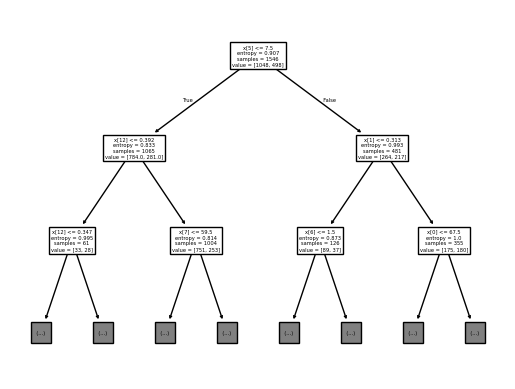

In [ ]:
## To view the tree

plot_tree(model_df_train, max_depth = 2)

In [ ]:
# To test the model

df_test['Prediction'] = model_df_train.predict(df_test.drop('sleep_disorder', axis = 'columns'))
df_test

,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,heart_rate,daily_steps,sleep_disorder,...,diastolic_pressure,stress_to_sleep_ratio,quality_to_sleep_ratio,mean_arterial_pressure,pulse_pressure,stress_to_quality_ratio,gender_M,gender_F,sleep_diff_from_occupation_avg,Prediction
0,52.0,0.324561,8.5,6.0,37.0,5.0,1,88.0,4973.0,0,...,75.80,0.588235,0.705882,87.866667,36.20,0.833333,1,0,1.088596,0
1,49.0,0.264706,8.2,7.0,77.0,5.0,2,80.0,6698.0,0,...,77.25,0.609756,0.853659,93.166667,47.75,0.714286,0,1,-0.053922,0
2,30.0,0.278351,9.0,7.0,71.0,6.0,1,76.0,6954.0,0,...,80.00,0.666667,0.777778,93.333333,40.00,0.857143,1,0,1.312371,1
3,41.0,0.250000,7.5,6.0,38.0,5.0,2,77.0,5057.0,0,...,88.20,0.666667,0.800000,101.466667,39.80,0.833333,1,0,-0.339423,0
4,33.0,0.397959,8.2,8.0,59.0,7.0,1,65.0,5262.0,1,...,81.35,0.853659,0.975610,93.900000,37.65,0.875000,0,1,0.926531,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
382,22.0,0.321739,7.5,7.0,102.0,5.0,0,75.0,9479.0,0,...,74.50,0.666667,0.933333,86.333333,35.50,0.714286,1,0,-0.278261,0
383,34.0,0.278351,6.9,4.0,38.0,8.0,1,77.0,3603.0,0,...,73.10,1.159420,0.579710,86.733333,40.90,2.000000,0,1,-0.787629,0
384,53.0,0.527273,6.5,3.0,55.5,10.0,1,58.0,7078.0,1,...,74.55,1.538462,0.461538,85.366667,32.45,3.333333,0,1,-0.857273,1
385,30.0,0.324561,5.8,8.0,70.0,3.0,0,62.0,8655.0,0,...,66.95,0.517241,1.379310,78.966667,36.05,0.375000,1,0,-1.611404,0


In [ ]:
df_test[['sleep_disorder', 'Prediction']]

,sleep_disorder,Prediction
0,0,0
1,0,0
2,0,1
3,0,0
4,1,1
...,...,...
382,0,0
383,0,0
384,1,1
385,0,0


**FEATURE IMPORTANCE**

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": df_train.drop("sleep_disorder", axis="columns").columns,
    "Importance": model_df_train.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
7,heart_rate,0.094594
18,sleep_diff_from_occupation_avg,0.082006
10,diastolic_pressure,0.078045
0,age,0.077166
4,physical_activity_level,0.073832
11,stress_to_sleep_ratio,0.071355
8,daily_steps,0.070955
12,quality_to_sleep_ratio,0.070043
1,occupation,0.066042
14,pulse_pressure,0.064261


**CONFUSION MATRIX**

In [ ]:
TP = ((df_test['sleep_disorder'] == 1) & (df_test['Prediction'] == 1)).sum()
print(TP)

TN = ((df_test['sleep_disorder'] == 0) & (df_test['Prediction'] == 0)).sum()
print(TN)

FP = ((df_test['sleep_disorder'] == 0) & (df_test['Prediction'] == 1)).sum()
print(FP)

FN = ((df_test['sleep_disorder'] == 1) & (df_test['Prediction'] == 0)).sum()
print(FN)

41
182
80
84


In [ ]:
#+-----------------------------------+-- Predintion sleep disorder -+- Prediction no sleep disorder  -+
#|                                   |                              |                                  |
#|----------------------------------------------------------------------------------------------------+
#|   Reality sleep disorder          |            47                |               78                 |
#|   Reality no sleep disorder       |            84                |               178                |
#+----------------------------------------------------------------------------------------------------+

**PERFORMANCE METRICS**


`ACCURACY`

In [ ]:
accuracy_score(df_test['sleep_disorder'], df_test['Prediction'])

0.5762273901808785

`PRECISION`

In [ ]:
precision_score(df_test['sleep_disorder'], df_test['Prediction'])

0.33884297520661155

`RECALL`

In [ ]:
recall_score(df_test['sleep_disorder'], df_test['Prediction'])

0.328

`F1`

In [ ]:
f1_score(df_test['sleep_disorder'], df_test['Prediction'])

0.3333333333333333

`ROC`

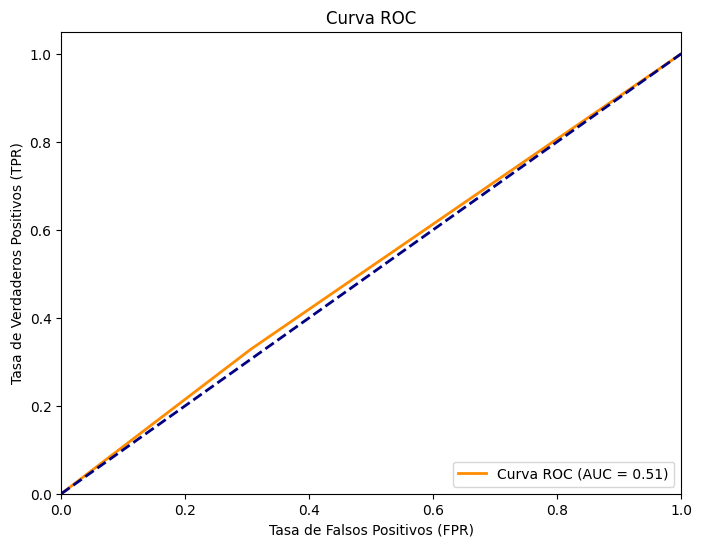

In [ ]:
y_true = df_test['sleep_disorder']  # Extract the true labels
y_scores = df_test['Prediction']  # Extract the model predictions

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# Calculate the area under the ROC curve (AUC)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()

## Model improvements

In [ ]:
# Create DataFrame with model results
resultados = pd.DataFrame({
    'Modelo': ['Modelo 1',],
    'Descripción': ['Decision tree'],
    'Accuracy': [0.5762273901808785],
    'Precision': [0.33884297520661155],
    'Recall': [0.328],
    'F1 Score': [0.3333333333333333],
    'ROC AUC': [0.51]
})

# Round to 3 decimal places
resultados = resultados.round(3)

# Display styled table
resultados.style.set_caption("Model Comparison") \
    .set_properties(**{'text-align': 'center'})

,Modelo,Descripción,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Modelo 1,Decision tree,0.576000,0.339000,0.328000,0.333000,0.510000


### Variable selection

Instead of using all available variables, we are going to use the most importante ones. In doing that, we will be looking at the conclusions we drew before, when talking about candidates features. We will remove the features that didn't show any relevant link to sleep disorder. Those would be gender, occupation and BMI category.


In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1546 entries, 0 to 1545
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             1546 non-null   float64
 1   occupation                      1546 non-null   float64
 2   sleep_duration                  1546 non-null   float64
 3   quality_of_sleep                1546 non-null   float64
 4   physical_activity_level         1546 non-null   float64
 5   stress_level                    1546 non-null   float64
 6   bmi_category                    1546 non-null   int64  
 7   heart_rate                      1546 non-null   float64
 8   daily_steps                     1546 non-null   float64
 9   sleep_disorder                  1546 non-null   int64  
 10  systolic_pressure               1546 non-null   float64
 11  diastolic_pressure              1546 non-null   float64
 12  stress_to_sleep_ratio           15

In [ ]:
df_modelo2 = df[['age', 'sleep_duration', 'quality_of_sleep',
                'physical_activity_level', 'stress_level', 'heart_rate',
                'daily_steps',  'sleep_disorder', 'systolic_pressure',
                'diastolic_pressure']]

We check the model performance

In [ ]:
df_train2, df_test2 = train_test_split(df_modelo2, test_size = 0.2, random_state = 7)
df_train4 = df_train2.copy()
df_test4 = df_test2.copy()

In [ ]:
tree_builder2 = DecisionTreeClassifier(criterion='entropy', random_state=7)
model_df_train2 = tree_builder2.fit(df_train2.drop('sleep_disorder', axis = 'columns'), df_train2['sleep_disorder'])

In [ ]:
df_test2['Prediction'] = model_df_train2.predict(df_test2.drop('sleep_disorder', axis = 'columns'))
df_test2.head()

,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,sleep_disorder,systolic_pressure,diastolic_pressure,Prediction
1461,59.0,7.4,4.0,48.0,8.0,94.0,4868.0,0,111.0,74.15,1
916,67.0,6.4,5.0,171.0,8.0,70.0,13858.0,0,122.0,82.30,1
1571,78.0,9.3,8.0,95.0,2.0,64.0,8835.0,0,113.0,71.45,0
1849,57.0,6.1,3.0,55.5,8.0,70.0,7789.0,1,107.0,70.55,1
1164,29.0,8.3,6.0,0.0,7.0,87.0,1561.0,0,122.0,74.30,0


In [ ]:
df_test2[['sleep_disorder', 'Prediction']]

,sleep_disorder,Prediction
1461,0,1
916,0,1
1571,0,0
1849,1,1
1164,0,0
...,...,...
1645,0,0
103,0,0
547,1,0
926,0,1


In [ ]:
accuracy_score(df_test2['sleep_disorder'], df_test2['Prediction'])

0.627906976744186

In [ ]:
precision_score(df_test2['sleep_disorder'], df_test2['Prediction'])

0.4409448818897638

In [ ]:
recall_score(df_test2['sleep_disorder'], df_test2['Prediction'])

0.43410852713178294

In [ ]:
f1_score(df_test2['sleep_disorder'], df_test2['Prediction'])

0.4375

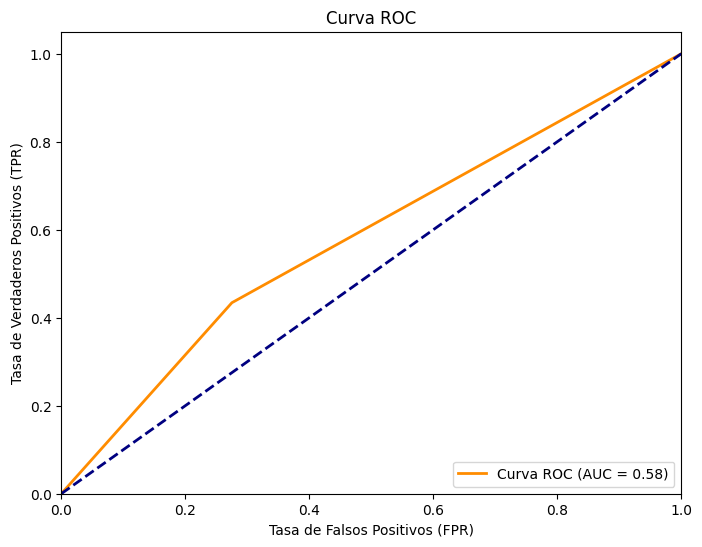

In [ ]:
y_true = df_test2['sleep_disorder']  # Extrae las etiquetas reales
y_scores = df_test2['Prediction']  # Extrae las predicciones del modelo

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# Calculate area under ROC curve (AUC)
roc_auc = auc(fpr, tpr)

# Graph ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()

In [ ]:
feature_importance2 = pd.DataFrame({
    "Feature": df_train2.drop("sleep_disorder", axis="columns").columns,
    "Importance": model_df_train2.feature_importances_
})

feature_importance2 = feature_importance2.sort_values(
    by="Importance",
    ascending=False
)

feature_importance2

,Feature,Importance
6,daily_steps,0.162579
0,age,0.155831
5,heart_rate,0.120872
1,sleep_duration,0.118418
8,diastolic_pressure,0.110356
3,physical_activity_level,0.099670
4,stress_level,0.080504
2,quality_of_sleep,0.077330
7,systolic_pressure,0.074440


In [ ]:
# Create DataFrame with model results
resultados = pd.DataFrame({
    'Modelo': ['Modelo 1', 'Modelo 2'],
    'Descripción': ['Decision tree', 'Decision tree + feature selection'],
    'Accuracy': [0.5762273901808785, 0.627906976744186],
    'Precision': [0.33884297520661155, 0.4409448818897638],
    'Recall': [0.328, 0.43410852713178294],
    'F1 Score': [0.3333333333333333, 0.4375],
    'ROC AUC': [0.51, 0.58]
})

# Round to 3 decimal places
resultados = resultados.round(3)

# Display styled table
resultados.style.set_caption("Model Comparison") \
    .set_properties(**{'text-align': 'center'})

,Modelo,Descripción,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Modelo 1,Decision tree,0.576000,0.339000,0.328000,0.333000,0.510000
1,Modelo 2,Decision tree + feature selection,0.628000,0.441000,0.434000,0.438000,0.580000


### SMOTE

In [ ]:
X_train3 = df_train2.drop('sleep_disorder', axis='columns')
y_train3 = df_train2['sleep_disorder']

smote = SMOTE(random_state=7)
X_train2_bal, y_train2_bal = smote.fit_resample(X_train2, y_train2)

tree_builder2_smote = DecisionTreeClassifier(criterion='entropy', random_state=7)
tree_builder2_smote.fit(X_train2_bal, y_train2_bal)

y_proba2_smote = tree_builder2_smote.predict_proba(df_test2[columnas_features])[:, 1]
y_pred2_smote = (y_proba2_smote >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_true2, y_pred2_smote))
print("F1:", f1_score(y_true2, y_pred2_smote))
print("Balanced accuracy:", balanced_accuracy_score(y_true2, y_pred2_smote))

Accuracy: 0.5813953488372093
F1: 0.31932773109243695
Balanced accuracy: 0.5096899224806202


In [ ]:
X_train3 = df_train2.drop('sleep_disorder', axis='columns')
y_train3 = df_train2['sleep_disorder']
X_test3 = df_test2.drop('sleep_disorder', axis='columns')
y_test3 = df_test2['sleep_disorder']

In [ ]:
smote = SMOTE(random_state = 7)
X_train_bal3, y_train_bal3 = smote.fit_resample(X_train3, y_train3)

In [ ]:
tree_builder3 = DecisionTreeClassifier(criterion='entropy', random_state = 7)
model_df_train3 = tree_builder3.fit(X_train_bal3, y_train_bal3)

In [ ]:
feature_columns = X_train3.columns # Get feature columns from the training set

X_test3['Prediction'] = model_df_train3.predict(X_test3[feature_columns])
X_test3['sleep_disorder'] = y_test3.values
X_test3

,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,systolic_pressure,diastolic_pressure,Prediction,sleep_disorder
1461,59.0,7.4,4.0,48.0,8.0,94.0,4868.0,111.0,74.15,1,0
916,67.0,6.4,5.0,171.0,8.0,70.0,13858.0,122.0,82.30,1,0
1571,78.0,9.3,8.0,95.0,2.0,64.0,8835.0,113.0,71.45,0,0
1849,57.0,6.1,3.0,55.5,8.0,70.0,7789.0,107.0,70.55,0,1
1164,29.0,8.3,6.0,0.0,7.0,87.0,1561.0,122.0,74.30,1,0
...,...,...,...,...,...,...,...,...,...,...,...
1645,74.0,7.5,5.0,108.0,9.0,54.0,11163.0,112.0,68.80,0,0
103,62.0,6.9,4.0,116.0,6.0,58.0,9707.0,128.0,87.20,0,0
547,78.0,7.3,5.0,55.0,9.0,75.0,4449.0,117.0,79.05,0,1
926,26.0,5.7,6.0,113.0,9.0,67.0,10572.0,122.0,81.30,0,0


In [ ]:
X_test3[['sleep_disorder', 'Prediction']]

,sleep_disorder,Prediction
1461,0,1
916,0,1
1571,0,0
1849,1,0
1164,0,1
...,...,...
1645,0,0
103,0,0
547,1,0
926,0,0


In [ ]:
accuracy_score(X_test3['sleep_disorder'], X_test3['Prediction'])

0.5813953488372093

In [ ]:
precision_score(X_test3['sleep_disorder'], X_test3['Prediction'])

0.3486238532110092

In [ ]:
recall_score(X_test3['sleep_disorder'], X_test3['Prediction'])

0.29457364341085274

In [ ]:
f1_score(X_test3['sleep_disorder'], X_test3['Prediction'])

0.31932773109243695

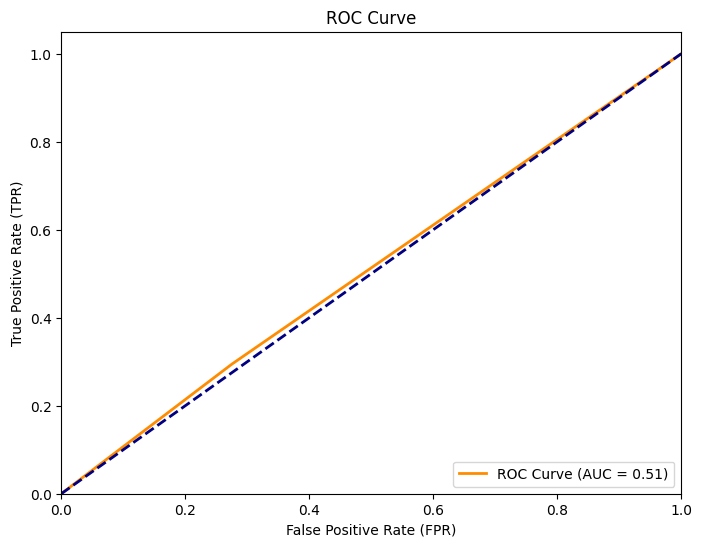

In [ ]:
y_true = X_test3['sleep_disorder']  # Extract the true labels
y_scores = X_test3['Prediction']  # Extract the model predictions

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# Calculate the Area Under the ROC Curve (AUC)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC Curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

In [ ]:
# Create DataFrame with model results
resultados = pd.DataFrame({
    'Modelo': ['Modelo 1', 'Modelo 2', 'Modelo 3'],
    'Descripción': ['Decision Tree', 'Decision Tree + feature selection', 'Decision Tree + feature selection + SMOTE'],
    'Accuracy': [0.5762273901808785, 0.627906976744186, 0.5813953488372093],
    'Precision': [0.33884297520661155, 0.4409448818897638, 0.3486238532110092],
    'Recall': [0.328, 0.43410852713178294, 0.29457364341085274],
    'F1 Score': [0.3333333333333333, 0.4375, 0.31932773109243695],
    'ROC AUC': [0.51, 0.58, 0.51]
})


# Round to 3 decimal places
resultados = resultados.round(3)

# Display styled table
resultados.style.set_caption("Model Comparison") \
    .set_properties(**{'text-align': 'center'})

,Modelo,Descripción,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Modelo 1,Decision Tree,0.576000,0.339000,0.328000,0.333000,0.510000
1,Modelo 2,Decision Tree + feature selection,0.628000,0.441000,0.434000,0.438000,0.580000
2,Modelo 3,Decision Tree + feature selection + SMOTE,0.581000,0.349000,0.295000,0.319000,0.510000


### Tree pruning

In [ ]:
tree_builder4 = DecisionTreeClassifier(criterion = 'entropy', random_state = 7, max_depth = 7, min_samples_leaf= 12 )
model_df_train4 = tree_builder4.fit(df_train4.drop('sleep_disorder', axis = 'columns'), df_train4['sleep_disorder'])

In [ ]:
df_test4['Prediction'] = model_df_train4.predict(X_test_features)
df_test4.head()

,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,sleep_disorder,systolic_pressure,diastolic_pressure,Prediction
1461,59.0,7.4,4.0,48.0,8.0,94.0,4868.0,0,111.0,74.15,1
916,67.0,6.4,5.0,171.0,8.0,70.0,13858.0,0,122.0,82.30,0
1571,78.0,9.3,8.0,95.0,2.0,64.0,8835.0,0,113.0,71.45,0
1849,57.0,6.1,3.0,55.5,8.0,70.0,7789.0,1,107.0,70.55,0
1164,29.0,8.3,6.0,0.0,7.0,87.0,1561.0,0,122.0,74.30,1


In [ ]:
df_test4[['sleep_disorder', 'Prediction']]

,sleep_disorder,Prediction
1461,0,1
916,0,0
1571,0,0
1849,1,0
1164,0,1
...,...,...
1645,0,0
103,0,0
547,1,0
926,0,1


In [ ]:
accuracy_score(df_test4['sleep_disorder'], df_test4['Prediction'])

0.6537467700258398

In [ ]:
precision_score(df_test4['sleep_disorder'], df_test4['Prediction'])

0.4444444444444444

In [ ]:
recall_score(df_test4['sleep_disorder'], df_test4['Prediction'])

0.15503875968992248

In [ ]:
f1_score(df_test4['sleep_disorder'], df_test4['Prediction'])

0.22988505747126436

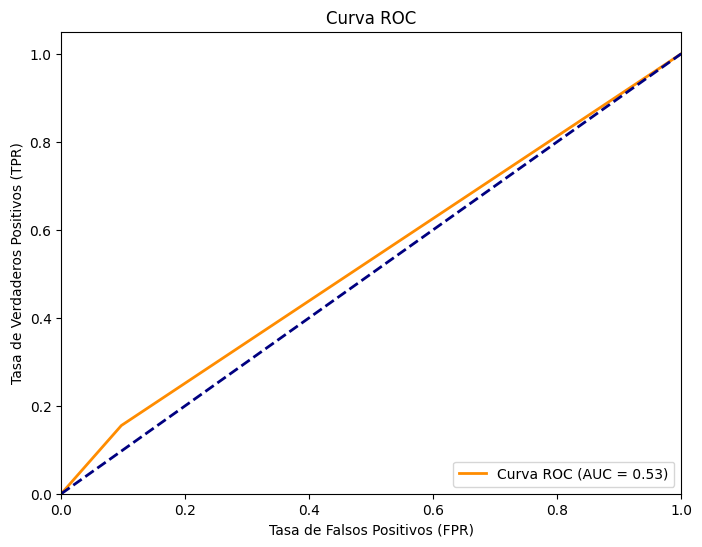

In [ ]:
y_true = df_test4['sleep_disorder']  # Extrae las etiquetas reales
y_scores = df_test4['Prediction']  # Extrae las predicciones del modelo

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# Calculate area under ROC curve (AUC)
roc_auc = auc(fpr, tpr)

# Graph ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()

In [ ]:
# Create DataFrame with model results
resultados = pd.DataFrame({
    'Modelo': ['Modelo 1', 'Modelo 2', 'Modelo 3', 'Modelo 4'],
    'Descripción': ['Decision Tree', 'Decision Tree + feature selection', 'Decision Tree + feature selection + SMOTE', 'Decision Tree + feature selection + tree pruning'],
    'Accuracy': [0.5762273901808785, 0.627906976744186, 0.5813953488372093, 0.6537467700258398],
    'Precision': [0.33884297520661155, 0.4409448818897638, 0.3486238532110092, 0.4444444444444444],
    'Recall': [0.328, 0.43410852713178294, 0.29457364341085274, 0.15503875968992248],
    'F1 Score': [0.3333333333333333, 0.4375, 0.31932773109243695, 0.22988505747126436],
    'ROC AUC': [0.51, 0.58, 0.51, 0.53]
})

# Round to 3 decimal places
resultados = resultados.round(3)

# Display styled table
resultados.style.set_caption("Model Comparison") \
    .set_properties(**{'text-align': 'center'})

,Modelo,Descripción,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Modelo 1,Decision Tree,0.576000,0.339000,0.328000,0.333000,0.510000
1,Modelo 2,Decision Tree + feature selection,0.628000,0.441000,0.434000,0.438000,0.580000
2,Modelo 3,Decision Tree + feature selection + SMOTE,0.581000,0.349000,0.295000,0.319000,0.510000
3,Modelo 4,Decision Tree + feature selection + tree pruning,0.654000,0.444000,0.155000,0.230000,0.530000


### Threshold

In [ ]:
X5 = df_modelo2.drop(columns = 'sleep_disorder')
y5 = df_modelo2['sleep_disorder']

In [ ]:
X_train5, X_test5, y_train5, y_test5 = train_test_split(X5, y5, test_size = 0.2, random_state = 7, stratify = y5)

In [ ]:
tree_builder5 = DecisionTreeClassifier(criterion='entropy', random_state=7)
model_df_train5 = tree_builder5.fit(X_train_bal5, y_train_bal5)

In [ ]:
probabilities_matrix = model_df_train5.predict_proba(X_test5)
X_test5['Probabilidad'] = probabilities_matrix.T[1]
X_test5['sleep_disorder'] = y_test5.values
X_test5

,age,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,heart_rate,daily_steps,systolic_pressure,diastolic_pressure,Probabilidad,sleep_disorder
1962,80.0,8.7,5.0,51.0,7.0,84.0,5060.0,120.0,73.00,0.0,0
213,76.0,6.7,5.0,51.0,7.0,91.0,5403.0,122.0,82.30,0.0,1
1863,63.0,8.8,4.0,92.0,5.0,75.0,9364.0,118.0,75.70,0.0,0
1610,65.0,9.7,7.0,30.0,3.0,70.0,4709.0,131.0,90.15,0.0,0
1731,59.0,9.7,5.0,132.0,6.0,50.0,10514.0,130.0,84.50,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...
707,19.0,7.5,4.0,55.5,5.0,62.0,4508.0,114.0,73.10,1.0,1
1400,23.0,7.4,4.0,22.0,3.0,83.0,2031.0,118.0,74.70,0.0,0
1410,19.0,8.1,4.0,0.0,4.0,88.0,2528.0,110.0,75.50,0.0,1
544,42.0,7.3,9.0,24.0,7.0,85.0,4326.0,131.0,84.15,1.0,1


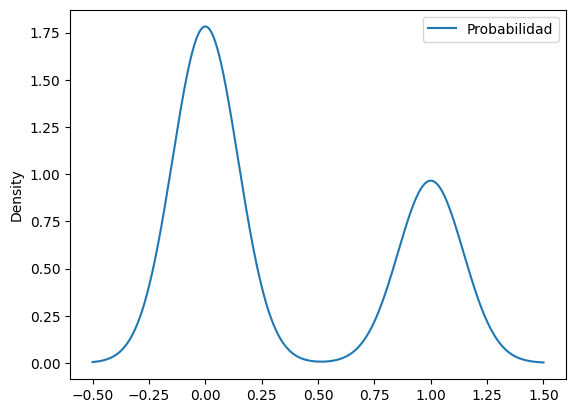

In [ ]:
plt.cla()
fig = X_test5['Probabilidad'].plot(kind = 'kde', legend = True)
display()

In [ ]:
def transform_prediction (probabilidad):
  if probabilidad >= 0.10:
    return 1
  else:
    return 0

In [ ]:
X_test5['Prediction_Umbral'] = X_test5['Probabilidad'].apply(transform_prediction)

In [ ]:
X_test5[['sleep_disorder', 'Prediction_Umbral']]

,sleep_disorder,Prediction_Umbral
1962,0,0
213,1,0
1863,0,0
1610,0,0
1731,0,0
...,...,...
707,1,1
1400,0,0
1410,1,0
544,1,1


In [ ]:
accuracy_score(X_test5['sleep_disorder'], X_test5['Prediction_Umbral'])

0.5633074935400517

In [ ]:
precision_score(X_test5['sleep_disorder'], X_test5['Prediction_Umbral'])

0.3382352941176471

In [ ]:
recall_score(X_test5['sleep_disorder'], X_test5['Prediction_Umbral'])

0.368

In [ ]:
f1_score(X_test5['sleep_disorder'], X_test5['Prediction_Umbral'])

0.3524904214559387

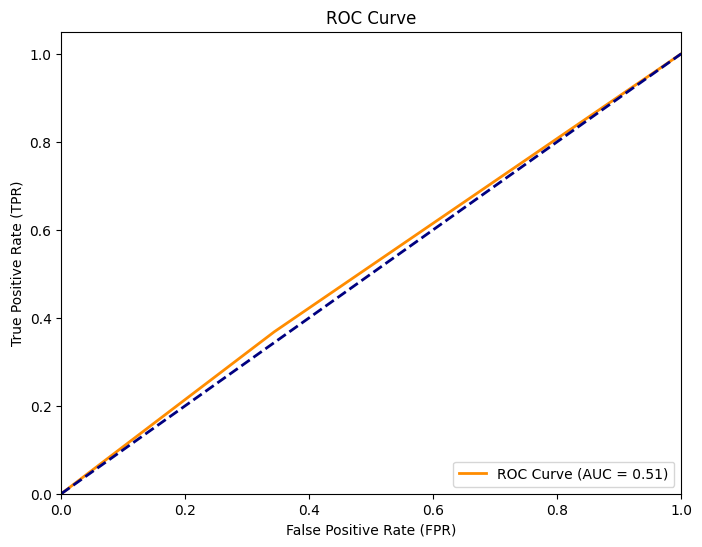

In [ ]:
y_true = X_test5['sleep_disorder']  # Extract the true labels
y_scores = X_test5['Prediction_Umbral']  # Extract the model predictions

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# Calculate the Area Under the ROC Curve (AUC)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC Curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

In [ ]:
# Create DataFrame with model results
resultados = pd.DataFrame({
    'Modelo': ['Modelo 1', 'Modelo 2', 'Modelo 3', 'Modelo 4', 'Modelo 5'],
    'Descripción': ['Decision Tree', 'Decision Tree + feature selection', 'Decision Tree + feature selection + SMOTE', 'Decision Tree + feature selection + tree pruning', 'Decision Tree + feature selection + tree pruning + threshold'],
    'Accuracy': [0.5762273901808785, 0.627906976744186, 0.5813953488372093, 0.6537467700258398, 0.3669250645994832],
    'Precision': [0.33884297520661155, 0.4409448818897638, 0.3486238532110092, 0.4444444444444444, 0.32098765432098764],
    'Recall': [0.328, 0.43410852713178294, 0.29457364341085274, 0.15503875968992248, 0.8062015503875969],
    'F1 Score': [0.3333333333333333, 0.4375, 0.31932773109243695, 0.22988505747126436, 0.45916114790286977],
    'ROC AUC': [0.51, 0.58, 0.51, 0.53, 0.48]
})

# Round to 3 decimal places
resultados = resultados.round(3)

# Display styled table
resultados.style.set_caption("Model Comparison") \
    .set_properties(**{'text-align': 'center'})

,Modelo,Descripción,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Modelo 1,Decision Tree,0.576000,0.339000,0.328000,0.333000,0.510000
1,Modelo 2,Decision Tree + feature selection,0.628000,0.441000,0.434000,0.438000,0.580000
2,Modelo 3,Decision Tree + feature selection + SMOTE,0.581000,0.349000,0.295000,0.319000,0.510000
3,Modelo 4,Decision Tree + feature selection + tree pruning,0.654000,0.444000,0.155000,0.230000,0.530000
4,Modelo 5,Decision Tree + feature selection + tree pruning + threshold,0.367000,0.321000,0.806000,0.459000,0.480000


We dont know why but we lost the metric values for the model 5. We ran it and we obtain that values, but know it gives another. We think that it is because instead of giving us probabilities, it gives us 1 or 0, so we cant really apply the threshold

## Profit matrix

In [ ]:
#+-----------------------------------+-- Prediction sleep disorder -+- Prediction no sleep disorder  -+
#|                                   |                              |                                 |
#|----------------------------------------------------------------------------------------------------+
#|   Reality sleep disorder          |            + 800             |              - 5000             |
#|   Reality no sleep disorder       |            - 300             |                 0               |
#+----------------------------------------------------------------------------------------------------+

### Model 2

VP: 55 × 800 = 44.000 €
FN: 74 × (−5.000) = −370.000 €
FP: 70 × (−300) = −21.000 €
VN: 188 × 0 = 0 €

Beneficio total = -347.000 €

### Model 5

VP: 103 × 800 = 82.400 €
FN: 26 × (−5.000) = −130.000 €
FP: 219 × (−300) = −65.700 €
VN: 39 × 0 = 0 €

Beneficio total = -113.000 €

# CONCLUSION

Although Model 5 has a lower precision (0.32 vs. 0.44), it achieves a much higher recall (0.80 vs. 0.43), allowing it to correctly identify a substantially larger proportion of patients with sleep disorders. Consequently, the number of false negatives is greatly reduced (26 vs. 74).

Given that the proposed profit matrix assigns a much higher cost to false negatives (€−5,000) than to false positives (€−300), the reduction in missed diagnoses more than compensates for the increase in unnecessary follow-up examinations. As a result, Model 5 yields a considerably smaller economic loss (€−113,300) than Model 1 (€−347,000), making it the preferred model from both an economic and a clinical perspective.